
# Notebook 10 — Attack Injection Pipeline

## Overview

This notebook implements the approved attack scenarios for **Mubsir: AI-Based Detection of Channel-Rotating Low-and-Slow Insider Data Exfiltration**.

Building on the validated attacker assignments from Notebook 08 and the daily attack schedules from Notebook 09, this notebook injects simulated malicious activity into a separate copy of the original User-Day dataset.

The injection is performed at the **User-Day aggregation level** by increasing event counts across three channels: Email, USB, and HTTP. All modifications follow the approved attack windows, channel schedules, switching patterns, synchronization configurations, and stealth settings.

The original dataset, including all 4,000 users and the immutable baseline period, remains unchanged.

## Objectives

1. **Prepare Approved Inputs:** Load and verify the approved scenario assignments, validated daily attack schedules, original User-Day data, and required behavioral references.

2. **Build the Attacker Master Table:** Consolidate all approved decisions into one comprehensive record for each of the 400 attackers.

3. **Prepare Injection Parameters:** Apply the approved count-based injection formulas and stealth settings using the existing behavioral baselines.

4. **Plan Daily Event Increments:** Determine the number of additional events for each scheduled user, day, and channel.

5. **Execute Attack Injection:** Apply the planned increments to a separate copy of the original User-Day data without modifying natural activity outside the approved injection scope.

6. **Record Every Modification:** Generate a detailed injection log containing the attacker, scenario identifier, date, channel, original event count, injected increment, and resulting event count.

7. **Perform Execution Integrity Checks:** Verify that the executed modifications match the approved injection plan and that the original data remain unchanged.

## Injection Scope

- **Population:** 4,000 original users, including 400 approved attackers.
- **Channels:** Email, USB, and HTTP.
- **Injection Period:** January 1, 2011 – June 1, 2011, restricted to approved attack windows and active workdays.
- **Immutable Baseline:** January 2, 2010 – December 31, 2010.
- **Injection Method:** Count-based modification of aggregated User-Day activity.
- **Protected Days:** Forced off-days and all non-targeted user-days.
- **Protected Channels:** All channels not explicitly scheduled for injection.

## Expected Outputs

- **Final Attacker Scenario Master:** A consolidated table of the 400 approved attackers and their scenario decisions.
- **Injection Plan:** Planned event-count increments for each targeted user-day-channel combination.
- **Injected User-Day Dataset (Intermediate):** A complete copy of the original User-Day dataset containing both natural and injected activity.
- **Injection Log:** A detailed, traceable record of every executed modification.
- **Execution QA Reports:** Checks confirming that injection operations respect the approved scenarios and source-data boundaries.

## Notebook Boundaries

This notebook is responsible for **attack injection and modification traceability only**.

Independent validation and Ground Truth generation will be performed in **Notebook 11 — Ground Truth and Quality Validation**.

Final behavioral feature updates, new attack-related feature engineering, and preparation of the final machine-learning datasets will be performed in **Notebook 12 — Injected Feature Engineering and Validation**.

No original source dataset or previously approved scenario assignment will be overwritten.



## 10.1 — Input Inventory & Integrity Verification

### Objective

Establish a verified, read-only input foundation for the Attack Injection Pipeline before constructing attacker records or modifying event counts.

This section reuses the approved decisions from Notebooks 08 and 09 and the original processed User-Day dataset.

### Required Inputs

1. **Approved Attacker Scenarios — Notebook 08**
   - The 400 approved attackers.
   - Scenario identifiers, attack windows, duration, channel configurations, switching levels, stealth settings, and forced off-day assignments.

2. **Validated Daily Attack Schedule — Notebook 09**
   - Approved user-day schedules.
   - Primary Channels and scheduled channel sets.
   - Synchronization days, switching indicators, and forced off-days.

3. **Selected Synchronization Targets — Notebook 09**
   - Per-attacker synchronization counts.
   - Rule selections, feasible switching evidence, and permitted fallbacks.

4. **Original User-Day Dataset**
   - The complete natural dataset covering all 4,000 users.
   - Original Email, USB, and HTTP event counts.
   - Immutable historical baseline and future activity periods.

5. **Behavioral Reference Inventory**
   - Identify the existing baseline/reference artifacts required for the approved count-based injection formulas.
   - Defer formula-specific loading and validation to Section 10.3.

### Integrity Verification

- Resolve input paths within the existing project structure.
- Verify required files and schemas.
- Validate exported file hashes against available manifests.
- Confirm unique user and user-day keys.
- Confirm the approved 400-attacker population.
- Verify scenario identities across Notebook 08 and Notebook 09.
- Confirm the original User-Day population and date range.
- Confirm that scheduled user-days are present in the source dataset.
- Confirm that the immutable baseline period is separate from the approved attack period.

### Outputs

- `INPUT_PATHS_10`: Resolved input file paths.
- `approved_assignments_10`: Verified Notebook 08 assignments.
- `daily_schedule_10`: Verified Notebook 09 daily schedule.
- `sync_targets_10`: Verified synchronization selections.
- `source_user_day_10`: Original User-Day dataset, loaded without modification.
- `input_inventory_10`: Required input inventory.
- `behavioral_reference_inventory_10`: Available behavioral reference candidates.
- `input_integrity_qa_10`: Input integrity checks.

### Scope

This section performs input discovery, loading, and validation only.

It does not construct the final attacker master table, recalculate baselines, determine injection increments, inject events, or export files.

### Expected Outcome

Verified inputs and an auditable foundation for Section 10.2 — Final Attacker Scenario Master Table.


In [13]:

# ============================================================
# NOTEBOOK 10 — SECTION 10.1
# INPUT INVENTORY & INTEGRITY VERIFICATION
#
# Read-only | No baseline recalculation | No injection
# ============================================================

from pathlib import Path
import hashlib
import json

import pandas as pd
from IPython.display import display


# ------------------------------------------------------------
# STEP 1 — Resolve existing project structure
# ------------------------------------------------------------

def find_simulation_root_101():

    current = Path.cwd().resolve()

    for candidate in [current, *current.parents]:

        if (
            candidate.name == "New_Attack_Simulation"
            and (candidate / "reports").is_dir()
        ):
            return candidate

        nested = candidate / "New_Attack_Simulation"

        if (
            nested.is_dir()
            and (nested / "reports").is_dir()
        ):
            return nested

    raise FileNotFoundError(
        "New_Attack_Simulation root not found."
    )


ROOT_10 = find_simulation_root_101()

REPORT_08_10 = (
    ROOT_10
    / "reports"
    / "08_Attacker_Selection_and_Scenario_Assignment"
)

REPORT_09_10 = (
    ROOT_10
    / "reports"
    / "09_PreInjection_Dry_Run"
)

SOURCE_PATH_10 = (
    ROOT_10.parent
    / "Data_Engineering"
    / "Data_engineering"
    / "data"
    / "processed"
    / "user_day_r62_v1.parquet"
)

# Destination path only; do not create it yet.
REPORT_10 = (
    ROOT_10
    / "reports"
    / "10_Attack_Injection_Pipeline"
)


# ------------------------------------------------------------
# STEP 2 — Register required input files
# ------------------------------------------------------------

INPUT_PATHS_10 = {
    "approved_assignments": (
        REPORT_08_10
        / "approved_attacker_scenarios_r62.parquet"
    ),

    "daily_schedule": (
        REPORT_09_10
        / "daily_attack_schedule_r62.parquet"
    ),

    "synchronization_targets": (
        REPORT_09_10
        / "selected_sync_targets_r62.parquet"
    ),

    "independent_user_audit": (
        REPORT_09_10
        / "independent_schedule_user_audit.csv"
    ),

    "notebook08_manifest": (
        REPORT_08_10 / "export_manifest.json"
    ),

    "notebook09_manifest": (
        REPORT_09_10 / "export_manifest.json"
    ),

    "original_user_day": SOURCE_PATH_10,
}

missing_101 = [
    f"{name}: {path}"
    for name, path in INPUT_PATHS_10.items()
    if not path.is_file()
]

if missing_101:
    raise FileNotFoundError(
        "Missing required inputs:\n"
        + "\n".join(missing_101)
    )



# ------------------------------------------------------------
# STEP 3 — Verify exported artifact hashes
#
# Supports:
# Notebook 08: manifest["files"] (dictionary)
# Notebook 09: manifest["artifacts"] (list)
# ------------------------------------------------------------

def sha256_101(path):

    digest = hashlib.sha256()

    with open(path, "rb") as file:
        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b"",
        ):
            digest.update(chunk)

    return digest.hexdigest()


def verify_manifest_entry_101(manifest_path, artifact_path):

    manifest = json.loads(
        manifest_path.read_text(encoding="utf-8")
    )

    filename = artifact_path.name

    # Notebook 08 format
    if isinstance(manifest.get("files"), dict):

        entries = manifest["files"]

    # Notebook 09 format
    elif isinstance(manifest.get("artifacts"), list):

        entries = {
            item["filename"]: item
            for item in manifest["artifacts"]
        }

    else:
        raise RuntimeError(
            f"Unsupported manifest structure: {manifest_path}"
        )

    if filename not in entries:
        raise RuntimeError(
            f"File not listed in manifest: {filename}"
        )

    entry = entries[filename]

    expected_hash = entry.get("sha256")
    expected_size = entry.get("size_bytes")

    if not expected_hash or expected_size is None:
        raise RuntimeError(
            f"Incomplete manifest entry: {filename}"
        )

    actual_hash = sha256_101(artifact_path)
    actual_size = artifact_path.stat().st_size

    if actual_hash.lower() != expected_hash.lower():
        raise RuntimeError(
            f"SHA-256 mismatch: {filename}"
        )

    if actual_size != int(expected_size):
        raise RuntimeError(
            f"File size mismatch: {filename}"
        )

    return True


hash_08_101 = verify_manifest_entry_101(
    INPUT_PATHS_10["notebook08_manifest"],
    INPUT_PATHS_10["approved_assignments"],
)

hash_09_schedule_101 = verify_manifest_entry_101(
    INPUT_PATHS_10["notebook09_manifest"],
    INPUT_PATHS_10["daily_schedule"],
)

hash_09_targets_101 = verify_manifest_entry_101(
    INPUT_PATHS_10["notebook09_manifest"],
    INPUT_PATHS_10["synchronization_targets"],
)

hash_09_audit_101 = verify_manifest_entry_101(
    INPUT_PATHS_10["notebook09_manifest"],
    INPUT_PATHS_10["independent_user_audit"],
)



# ------------------------------------------------------------
# STEP 4 — Load read-only working copies
# ------------------------------------------------------------

approved_assignments_10 = pd.read_parquet(
    INPUT_PATHS_10["approved_assignments"]
)

daily_schedule_10 = pd.read_parquet(
    INPUT_PATHS_10["daily_schedule"]
)

sync_targets_10 = pd.read_parquet(
    INPUT_PATHS_10["synchronization_targets"]
)

independent_user_audit_10 = pd.read_csv(
    INPUT_PATHS_10["independent_user_audit"],
    encoding="utf-8-sig",
    dtype={"user": "string"},
)

source_user_day_10 = pd.read_parquet(
    INPUT_PATHS_10["original_user_day"]
)

for frame in (
    approved_assignments_10,
    daily_schedule_10,
    sync_targets_10,
    independent_user_audit_10,
    source_user_day_10,
):
    frame["user"] = frame["user"].astype("string")

for frame in (
    daily_schedule_10,
    source_user_day_10,
):
    frame["day"] = pd.to_datetime(
        frame["day"], errors="raise"
    ).dt.normalize()


# ------------------------------------------------------------
# STEP 5 — Validate required schemas and primary keys
# ------------------------------------------------------------

REQUIRED_COLUMNS_101 = {
    "approved_assignments": {
        "user",
        "scenario_option_id",
        "window_workdays",
        "window_start",
        "window_end",
        "channel_configuration",
        "switching_level",
        "stealth_level",
        "stealth_multiplier",
        "formula_id",
        "forced_offdays",
        "proposed_active_days",
    },

    "daily_schedule": {
        "user",
        "scenario_option_id",
        "day",
        "workday_index",
        "is_active_day",
        "is_forced_offday",
        "primary_channel_mask",
        "scheduled_channel_mask",
        "is_switch",
    },

    "synchronization_targets": {
        "user",
        "scenario_option_id",
        "target_2ch_days",
        "target_3ch_days",
        "attainable_switch_mask",
        "rule_status",
    },

    "independent_user_audit": {
        "user",
        "scenario_option_id",
        "two_channel_days",
        "three_channel_days",
        "switches",
    },

    "original_user_day": {
        "user",
        "day",
        "is_weekend",
        "logon_count",
        "external_email_count",
        "usb_copy_count",
        "www_upload_count",
    },
}

frames_101 = {
    "approved_assignments": approved_assignments_10,
    "daily_schedule": daily_schedule_10,
    "synchronization_targets": sync_targets_10,
    "independent_user_audit": independent_user_audit_10,
    "original_user_day": source_user_day_10,
}

schema_results_101 = {}

for name, expected in REQUIRED_COLUMNS_101.items():

    missing_columns = (
        expected - set(frames_101[name].columns)
    )

    schema_results_101[name] = (
        len(missing_columns) == 0
    )

    if missing_columns:
        raise RuntimeError(
            f"{name} missing columns: "
            f"{sorted(missing_columns)}"
        )

unique_users_101 = all(
    len(frame) == 400
    and frame["user"].is_unique
    and frame["user"].notna().all()
    for frame in (
        approved_assignments_10,
        sync_targets_10,
        independent_user_audit_10,
    )
)

source_keys_101 = bool(
    not source_user_day_10.duplicated(
        ["user", "day"]
    ).any()
    and source_user_day_10[
        ["user", "day"]
    ].notna().all().all()
)

schedule_keys_101 = bool(
    not daily_schedule_10.duplicated(
        ["user", "day"]
    ).any()
    and daily_schedule_10[
        ["user", "day"]
    ].notna().all().all()
)


# ------------------------------------------------------------
# STEP 6 — Cross-file attacker and scenario identity
# ------------------------------------------------------------

def identity_set_101(frame):

    return set(
        zip(
            frame["user"].astype(str),
            frame["scenario_option_id"].astype("string"),
        )
    )


approved_identities_101 = identity_set_101(
    approved_assignments_10
)

identity_valid_101 = all(
    identity_set_101(frame) == approved_identities_101
    for frame in (
        sync_targets_10,
        independent_user_audit_10,
    )
)

schedule_identity_101 = (
    daily_schedule_10[
        ["user", "scenario_option_id"]
    ]
    .drop_duplicates()
)

schedule_identity_valid_101 = bool(
    identity_set_101(schedule_identity_101)
    == approved_identities_101
)

approved_users_101 = set(
    approved_assignments_10["user"].astype(str)
)

source_users_101 = set(
    source_user_day_10["user"].astype(str)
)

population_valid_101 = bool(
    len(source_users_101) == 4000
    and approved_users_101.issubset(source_users_101)
)

# Every scheduled user-day must exist in original User-Day.
source_keys_set_101 = pd.MultiIndex.from_frame(
    source_user_day_10[["user", "day"]]
)

schedule_keys_set_101 = pd.MultiIndex.from_frame(
    daily_schedule_10[["user", "day"]]
)

schedule_source_valid_101 = bool(
    schedule_keys_set_101.isin(
        source_keys_set_101
    ).all()
)


# ------------------------------------------------------------
# STEP 7 — Baseline and injection-period boundaries
# ------------------------------------------------------------

BASELINE_START_10 = pd.Timestamp("2010-01-02")
BASELINE_END_10 = pd.Timestamp("2010-12-31")

ATTACK_START_10 = pd.Timestamp("2011-01-01")
ATTACK_END_10 = pd.Timestamp("2011-06-01")

source_dates_valid_101 = bool(
    source_user_day_10["day"].min()
    == BASELINE_START_10
    and
    source_user_day_10["day"].max()
    == ATTACK_END_10
)

schedule_dates_valid_101 = bool(
    daily_schedule_10["day"].between(
        ATTACK_START_10,
        ATTACK_END_10,
    ).all()
)

source_event_counts_valid_101 = True

for column in (
    "external_email_count",
    "usb_copy_count",
    "www_upload_count",
):

    values = pd.to_numeric(
        source_user_day_10[column],
        errors="coerce",
    )

    if not (
        values.notna().all()
        and values.ge(0).all()
        and values.eq(values.round()).all()
    ):
        source_event_counts_valid_101 = False


# ------------------------------------------------------------
# STEP 8 — Check schedule totals against approved targets
# ------------------------------------------------------------

active_101 = daily_schedule_10[
    "is_active_day"
].astype(bool)

offday_101 = daily_schedule_10[
    "is_forced_offday"
].astype(bool)

scheduled_counts_101 = (
    daily_schedule_10["scheduled_channel_mask"]
    .astype(int)
    .map(int.bit_count)
)

schedule_totals_valid_101 = bool(
    len(daily_schedule_10) == 10750
    and int(active_101.sum()) == 9080
    and int(offday_101.sum()) == 1670
    and active_101.eq(~offday_101).all()
    and
    int(scheduled_counts_101.eq(2).sum())
    == int(sync_targets_10["target_2ch_days"].sum())
    and
    int(scheduled_counts_101.eq(3).sum())
    == int(sync_targets_10["target_3ch_days"].sum())
    and
    int(daily_schedule_10["is_switch"].sum())
    == int(independent_user_audit_10["switches"].sum())
)


# ------------------------------------------------------------
# STEP 9 — Inventory existing behavioral references
#
# Discovery only: no baseline selection or recalculation.
# ------------------------------------------------------------

reference_records_101 = []

report_root_101 = ROOT_10 / "reports"

for folder in sorted(report_root_101.iterdir()):

    if not folder.is_dir():
        continue

    # Earlier notebook outputs only.
    folder_prefix = folder.name.split("_", 1)[0]

    if (
        not folder_prefix.isdigit()
        or int(folder_prefix) >= 10
    ):
        continue

    for path in folder.rglob("*"):

        if not path.is_file():
            continue

        if path.suffix.lower() not in {
            ".parquet", ".csv", ".json"
        }:
            continue

        if not any(
            term in path.name.lower()
            for term in (
                "baseline",
                "reference",
                "stealth",
                "formula",
                "profile",
            )
        ):
            continue

        reference_records_101.append({
            "source_notebook": folder.name,
            "filename": path.name,
            "path": str(path),
        })

behavioral_reference_inventory_10 = pd.DataFrame(
    reference_records_101,
    columns=[
        "source_notebook",
        "filename",
        "path",
    ],
)

# This is an inventory, not proof that all necessary
# formula-specific references are present.


# ------------------------------------------------------------
# STEP 10 — Consolidated input QA
# ------------------------------------------------------------

checks_101 = {
    "Required inputs exist":
        all(p.is_file() for p in INPUT_PATHS_10.values()),

    "Notebook 08 artifact hash verified":
        hash_08_101,

    "Notebook 09 artifact hashes verified":
        (
            hash_09_schedule_101
            and hash_09_targets_101
            and hash_09_audit_101
        ),

    "Required input schemas":
        all(schema_results_101.values()),

    "400 unique approved attacker records":
        unique_users_101,

    "Original User-Day keys unique":
        source_keys_101,

    "Daily schedule keys unique":
        schedule_keys_101,

    "Attacker scenario identities match":
        identity_valid_101
        and schedule_identity_valid_101,

    "4,000 original users preserved in source":
        population_valid_101,

    "All scheduled user-days exist in source":
        schedule_source_valid_101,

    "Original dataset date boundaries":
        source_dates_valid_101,

    "Schedule restricted to attack period":
        schedule_dates_valid_101,

    "Original event counts are valid":
        source_event_counts_valid_101,

    "Schedule totals match validated targets":
        schedule_totals_valid_101,
}

input_integrity_qa_10 = pd.DataFrame([
    {
        "check": name,
        "status": "PASS" if bool(ok) else "FAIL",
    }
    for name, ok in checks_101.items()
])

failed_101 = input_integrity_qa_10.loc[
    input_integrity_qa_10["status"].ne("PASS")
]

if not failed_101.empty:

    print("\nFAILED INPUT INTEGRITY CHECKS")
    display(failed_101)

    raise RuntimeError(
        "Section 10.1 input validation failed."
    )


# ------------------------------------------------------------
# STEP 11 — Readable input inventory
# ------------------------------------------------------------

inventory_rows_101 = []

for name, path in INPUT_PATHS_10.items():

    frame = frames_101.get(name)

    inventory_rows_101.append({
        "Input": name,
        "Rows": len(frame) if frame is not None else None,
        "Status": "VERIFIED",
    })

input_inventory_10 = pd.DataFrame(inventory_rows_101)

print("\nVERIFIED INPUT INVENTORY")
display(input_inventory_10)


# ------------------------------------------------------------
# STEP 12 — Concise final summary
# ------------------------------------------------------------

print("\n" + "=" * 56)
print("NOTEBOOK 10 — SECTION 10.1 SUMMARY")
print("=" * 56)

print(
    "Original users        :",
    source_user_day_10["user"].nunique()
)

print(
    "Original User-Day rows:",
    len(source_user_day_10)
)

print(
    "Approved attackers    :",
    len(approved_assignments_10)
)

print(
    "Scheduled user-days   :",
    len(daily_schedule_10)
)

print(
    "Active attack days    :",
    int(active_101.sum())
)

print(
    "Forced off-days       :",
    int(offday_101.sum())
)

print(
    "Behavioral candidates :",
    len(behavioral_reference_inventory_10)
)

print(
    "Input QA              :",
    f"{len(input_integrity_qa_10)}/"
    f"{len(input_integrity_qa_10)} PASS"
)

print("Source files modified : NO")
print("Attack injection      : NOT STARTED")
print("Files exported        : NO")
print("=" * 56)
print("SECTION 10.1 — PASS")



VERIFIED INPUT INVENTORY


,Input,Rows,Status
0,approved_assignments,400.0,VERIFIED
1,daily_schedule,10750.0,VERIFIED
2,synchronization_targets,400.0,VERIFIED
3,independent_user_audit,400.0,VERIFIED
4,notebook08_manifest,NaN,VERIFIED
5,notebook09_manifest,NaN,VERIFIED
6,original_user_day,1394010.0,VERIFIED



NOTEBOOK 10 — SECTION 10.1 SUMMARY
Original users        : 4000
Original User-Day rows: 1394010
Approved attackers    : 400
Scheduled user-days   : 10750
Active attack days    : 9080
Forced off-days       : 1670
Behavioral candidates : 7
Input QA              : 14/14 PASS
Source files modified : NO
Attack injection      : NOT STARTED
Files exported        : NO
SECTION 10.1 — PASS


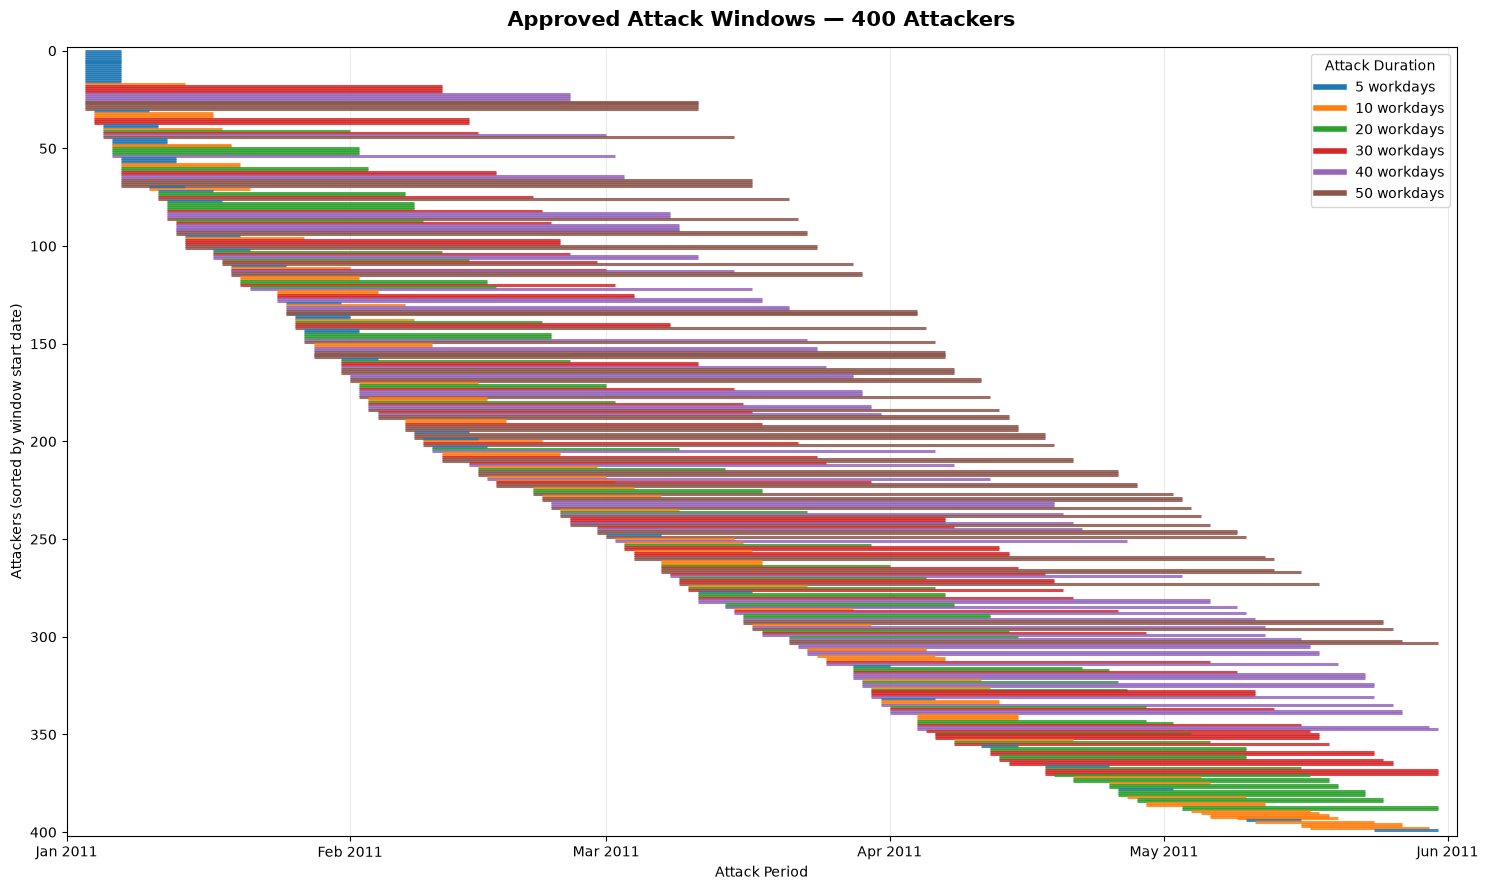

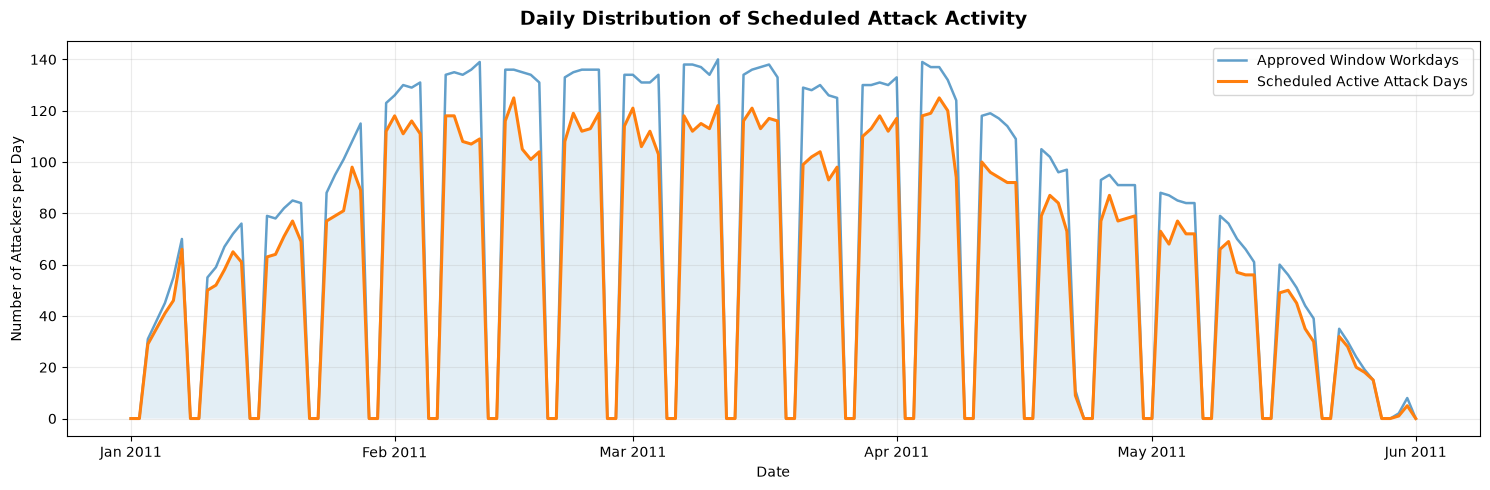

ATTACK WINDOW DISTRIBUTION SUMMARY
------------------------------------------------
Approved attackers       : 400
Earliest window start    : 2011-01-03
Latest window start      : 2011-05-24
Earliest window end      : 2011-01-07
Latest window end        : 2011-05-31
Peak concurrent activity : 125 attackers
Peak activity date       : 2011-02-15
Days with active attacks : 107
Source files modified    : NO
Files exported           : NO


In [14]:

# ============================================================
# ATTACK WINDOW DISTRIBUTION — VISUAL EXPLORATION
# Approved 400 attackers | 2011-01-01 to 2011-06-01
# Read-only | No injection | No exports
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from IPython.display import display

# ------------------------------------------------------------
# 1. Load approved windows and scheduled daily activity
# ------------------------------------------------------------

windows_viz = approved_assignments_10[
    ["user", "window_start", "window_end", "window_workdays"]
].copy()

schedule_viz = daily_schedule_10[
    ["user", "day", "is_active_day", "is_forced_offday"]
].copy()

windows_viz["window_start"] = pd.to_datetime(
    windows_viz["window_start"]
)
windows_viz["window_end"] = pd.to_datetime(
    windows_viz["window_end"]
)
schedule_viz["day"] = pd.to_datetime(
    schedule_viz["day"]
)

windows_viz = windows_viz.sort_values(
    ["window_start", "window_end", "user"]
).reset_index(drop=True)

assert len(windows_viz) == 400
assert windows_viz["user"].is_unique

ATTACK_START_VIZ = pd.Timestamp("2011-01-01")
ATTACK_END_VIZ = pd.Timestamp("2011-06-01")

assert windows_viz["window_start"].ge(ATTACK_START_VIZ).all()
assert windows_viz["window_end"].le(ATTACK_END_VIZ).all()


# ------------------------------------------------------------
# 2. Visualization A — All 400 attack windows
# ------------------------------------------------------------

durations_viz = sorted(
    windows_viz["window_workdays"].unique()
)

cmap_viz = plt.get_cmap("tab10")

duration_colors_viz = {
    duration: cmap_viz(i)
    for i, duration in enumerate(durations_viz)
}

segments_viz = [
    [
        (mdates.date2num(row.window_start), i),
        (mdates.date2num(row.window_end), i),
    ]
    for i, row in enumerate(
        windows_viz.itertuples(index=False)
    )
]

segment_colors_viz = [
    duration_colors_viz[int(duration)]
    for duration in windows_viz["window_workdays"]
]

fig, ax = plt.subplots(figsize=(15, 9))

collection = LineCollection(
    segments_viz,
    colors=segment_colors_viz,
    linewidths=2.2,
    alpha=0.85,
)

ax.add_collection(collection)

ax.set_xlim(
    ATTACK_START_VIZ,
    ATTACK_END_VIZ + pd.Timedelta(days=1)
)

ax.set_ylim(-2, len(windows_viz) + 2)

ax.invert_yaxis()

ax.xaxis.set_major_locator(
    mdates.MonthLocator()
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

ax.set_title(
    "Approved Attack Windows — 400 Attackers",
    fontsize=15,
    fontweight="bold",
    pad=15,
)

ax.set_xlabel("Attack Period")
ax.set_ylabel("Attackers (sorted by window start date)")

ax.grid(axis="x", alpha=0.25)

legend_items = [
    Line2D(
        [0], [0],
        color=duration_colors_viz[duration],
        lw=4,
        label=f"{duration} workdays",
    )
    for duration in durations_viz
]

ax.legend(
    handles=legend_items,
    title="Attack Duration",
    loc="upper right",
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. Visualization B — Daily distribution of activity
#
# Window days: approved user-workdays in the schedule.
# Active days: scheduled attack-active days, excluding
# forced off-days.
# ------------------------------------------------------------

date_range_viz = pd.date_range(
    ATTACK_START_VIZ,
    ATTACK_END_VIZ,
    freq="D",
)

window_counts_viz = (
    schedule_viz.groupby("day")
    .size()
    .reindex(date_range_viz, fill_value=0)
)

active_counts_viz = (
    schedule_viz.loc[
        schedule_viz["is_active_day"].astype(bool)
    ]
    .groupby("day")
    .size()
    .reindex(date_range_viz, fill_value=0)
)

fig, ax = plt.subplots(figsize=(15, 5))

ax.plot(
    date_range_viz,
    window_counts_viz,
    label="Approved Window Workdays",
    linewidth=1.8,
    alpha=0.7,
)

ax.plot(
    date_range_viz,
    active_counts_viz,
    label="Scheduled Active Attack Days",
    linewidth=2.2,
)

ax.fill_between(
    date_range_viz,
    active_counts_viz.to_numpy(),
    alpha=0.12,
)

ax.set_title(
    "Daily Distribution of Scheduled Attack Activity",
    fontsize=14,
    fontweight="bold",
    pad=12,
)

ax.set_xlabel("Date")
ax.set_ylabel("Number of Attackers per Day")

ax.xaxis.set_major_locator(
    mdates.MonthLocator()
)

ax.xaxis.set_major_formatter(
    mdates.DateFormatter("%b %Y")
)

ax.grid(alpha=0.25)
ax.legend()

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 4. Concise distribution statistics
# ------------------------------------------------------------

print("ATTACK WINDOW DISTRIBUTION SUMMARY")
print("-" * 48)

print("Approved attackers       :", len(windows_viz))
print("Earliest window start    :", windows_viz["window_start"].min().date())
print("Latest window start      :", windows_viz["window_start"].max().date())
print("Earliest window end      :", windows_viz["window_end"].min().date())
print("Latest window end        :", windows_viz["window_end"].max().date())

print(
    "Peak concurrent activity :",
    int(active_counts_viz.max()),
    "attackers"
)

print(
    "Peak activity date       :",
    active_counts_viz.idxmax().date()
)

print(
    "Days with active attacks :",
    int(active_counts_viz.gt(0).sum())
)

print("Source files modified    : NO")
print("Files exported           : NO")



## 10.2 — Injection Reference & Formula Preparation

### Objective

Identify and verify the approved count-based injection formulas, stealth parameters, and historical behavioral references required to calculate malicious event-count increments.

This section reuses the approved scenario assignments from Notebook 08 and the existing behavioral reference artifacts without creating a separate attacker master table.

### Input Sources

- **Notebook 08:** Approved formula identifiers, stealth levels, stealth multipliers, and channel configurations.
- **Previous baseline/reference artifacts:** Existing historical behavioral statistics and channel-specific reference values.
- **Original User-Day dataset:** Natural event counts for Email, USB, and HTTP.
- **Notebook 09:** Approved daily attack schedule, which determines when and where event increments may be applied.

### Preparation Procedure

1. Extract the formula identifiers and stealth configurations assigned to the 400 attackers.
2. Verify that all required injection parameters are present and valid.
3. Inspect existing behavioral reference artifacts and their available fields.
4. Identify which approved count-based reference values and formula definitions are available for injection.
5. Record unresolved formula definitions or missing behavioral references before calculating any increments.

### Count-Based Injection Scope

Only the following source event counts are eligible for modification:

| Channel | User-Day Field |
|---|---|
| Email | `external_email_count` |
| USB | `usb_copy_count` |
| HTTP | `www_upload_count` |

Data sizes, byte volumes, and payload lengths are excluded.

### Baseline Protection

The historical baseline period (2010-01-02 through 2010-12-31) remains immutable.

Existing behavioral references may be inspected and reused, but no baseline statistics are recalculated in this section.

### Validation and Readiness

Distinguish between:

- **Parameter Integrity:** The approved attacker parameters are complete and internally consistent.
- **Reference Availability:** The required source artifacts and fields are available.
- **Formula Readiness:** The precise approved count-increment calculations have been identified and can be implemented without assumptions.

Passing parameter integrity checks does not automatically imply injection readiness.

### Outputs

- `injection_parameter_audit_10`: Verified approved formula and stealth assignments.
- `formula_distribution_10`: Formula and stealth configuration distribution.
- `reference_schema_inventory_10`: Existing reference artifact schemas.
- `injection_reference_qa_10`: Preparation integrity checks.
- `formula_readiness_10`: Explicit readiness status and unresolved requirements.

### Scope

This section performs read-only inspection and preparation.

It does not generate event increments, modify User-Day records, recalculate baselines, execute injections, or export files.

### Expected Outcome

An evidence-based understanding of the approved injection formulas and their required inputs, ready for Daily Injection Planning once all formula dependencies are verified.


In [15]:

# ============================================================
# NOTEBOOK 10 — SECTION 10.2
# INJECTION REFERENCE & FORMULA PREPARATION
#
# Read-only | Count-based only
# No baseline recalculation | No injection | No exports
# ============================================================

from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import display


# ------------------------------------------------------------
# STEP 1 — Verify Section 10.1
# ------------------------------------------------------------

if not input_integrity_qa_10["status"].eq("PASS").all():
    raise RuntimeError("Section 10.1 must pass first.")

assignments_102 = approved_assignments_10.copy(deep=True)

REQUIRED_FIELDS_102 = [
    "user",
    "scenario_option_id",
    "channel_configuration",
    "stealth_level",
    "stealth_multiplier",
    "formula_id",
    "multiplier_configuration",
]

missing_102 = (
    set(REQUIRED_FIELDS_102)
    - set(assignments_102.columns)
)

if missing_102:
    raise RuntimeError(
        f"Missing approved fields: {sorted(missing_102)}"
    )

if len(assignments_102) != 400:
    raise RuntimeError("Expected exactly 400 attackers.")

assignments_102["user"] = (
    assignments_102["user"].astype("string")
)

if not assignments_102["user"].is_unique:
    raise RuntimeError("Duplicate approved attackers.")


# ------------------------------------------------------------
# STEP 2 — Validate formula IDs and stealth parameters
# ------------------------------------------------------------

def valid_text_102(series):
    values = series.astype("string").str.strip()
    return values.notna() & values.ne("")


formula_ids_102 = (
    assignments_102["formula_id"].astype("string")
)

stealth_levels_102 = (
    assignments_102["stealth_level"].astype("string")
)

multipliers_102 = pd.to_numeric(
    assignments_102["stealth_multiplier"],
    errors="coerce",
)

formula_ids_valid_102 = bool(
    valid_text_102(formula_ids_102).all()
)

stealth_levels_valid_102 = bool(
    valid_text_102(stealth_levels_102).all()
)

multipliers_valid_102 = bool(
    multipliers_102.notna().all()
    and np.isfinite(
        multipliers_102.to_numpy(dtype=float)
    ).all()
    and multipliers_102.gt(0).all()
)

configurations_valid_102 = bool(
    assignments_102["channel_configuration"].isin(
        ["E+U", "E+H", "U+H", "E+U+H"]
    ).all()
)


# ------------------------------------------------------------
# STEP 3 — Preserve approved parameter values
#
# No formula calculations or parameter reassignment.
# ------------------------------------------------------------

injection_parameter_audit_10 = (
    assignments_102[REQUIRED_FIELDS_102]
    .copy(deep=True)
)

injection_parameter_audit_10[
    "stealth_multiplier_numeric"
] = multipliers_102.to_numpy()

injection_parameter_audit_10[
    "parameter_status"
] = "PENDING_VALIDATION"

valid_rows_102 = (
    valid_text_102(formula_ids_102)
    & valid_text_102(stealth_levels_102)
    & multipliers_102.notna()
    & multipliers_102.gt(0)
    & assignments_102["channel_configuration"].isin(
        ["E+U", "E+H", "U+H", "E+U+H"]
    )
)

injection_parameter_audit_10.loc[
    valid_rows_102, "parameter_status"
] = "VALID"

formula_distribution_10 = (
    injection_parameter_audit_10
    .groupby(
        ["formula_id", "stealth_level"],
        dropna=False,
    )
    .agg(
        attackers=("user", "size"),
        distinct_multipliers=(
            "stealth_multiplier_numeric",
            "nunique",
        ),
        min_multiplier=(
            "stealth_multiplier_numeric",
            "min",
        ),
        max_multiplier=(
            "stealth_multiplier_numeric",
            "max",
        ),
    )
    .reset_index()
    .sort_values(
        ["formula_id", "stealth_level"]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# STEP 4 — Inspect existing behavioral reference schemas
#
# Read metadata/column names only.
# Do not recompute baseline statistics.
# ------------------------------------------------------------

def inspect_reference_102(path):

    path = Path(path)

    result = {
        "file": path.name,
        "format": path.suffix.lower(),
        "columns": [],
        "inspection": "NOT_INSPECTED",
    }

    if not path.is_file():
        result["inspection"] = "MISSING"
        return result

    try:

        suffix = path.suffix.lower()

        if suffix == ".parquet":

            import pyarrow.parquet as pq

            parquet_file = pq.ParquetFile(path)

            result["columns"] = (
                parquet_file.schema_arrow.names
            )
            result["inspection"] = "SCHEMA_READ"

        elif suffix == ".csv":

            header = pd.read_csv(
                path,
                nrows=0,
                encoding="utf-8-sig",
            )

            result["columns"] = header.columns.tolist()
            result["inspection"] = "HEADER_READ"

        elif suffix == ".json":

            # Avoid loading large JSON datasets just
            # to discover their general structure.
            if path.stat().st_size <= 5_000_000:

                with path.open(
                    "r", encoding="utf-8"
                ) as stream:
                    obj = json.load(stream)

                if isinstance(obj, dict):
                    result["columns"] = list(obj.keys())
                    result["inspection"] = "JSON_KEYS_READ"

                elif isinstance(obj, list):
                    result["inspection"] = (
                        "JSON_LIST_INSPECTED"
                    )

                    if obj and isinstance(obj[0], dict):
                        result["columns"] = (
                            list(obj[0].keys())
                        )

                else:
                    result["inspection"] = "JSON_SCALAR"

            else:
                result["inspection"] = (
                    "LARGE_JSON_METADATA_ONLY"
                )

        else:
            result["inspection"] = "UNSUPPORTED_FORMAT"

    except Exception as exc:

        result["inspection"] = (
            f"INSPECTION_ERROR: {type(exc).__name__}"
        )

    return result


reference_rows_102 = []

for record in behavioral_reference_inventory_10.itertuples(
    index=False
):

    path = Path(record.path)

    inspected = inspect_reference_102(path)

    reference_rows_102.append({
        "source_notebook": record.source_notebook,
        "filename": inspected["file"],
        "path": str(path),
        "format": inspected["format"],
        "column_count": len(inspected["columns"]),
        "column_names": inspected["columns"],
        "inspection": inspected["inspection"],
    })

reference_schema_inventory_10 = pd.DataFrame(
    reference_rows_102,
    columns=[
        "source_notebook",
        "filename",
        "path",
        "format",
        "column_count",
        "column_names",
        "inspection",
    ],
)


# ------------------------------------------------------------
# STEP 5 — Check the actual count-based source fields
# ------------------------------------------------------------

CHANNEL_COUNT_COLUMNS_102 = {
    "Email": "external_email_count",
    "USB": "usb_copy_count",
    "HTTP": "www_upload_count",
}

source_count_columns_valid_102 = all(
    col in source_user_day_10.columns
    for col in CHANNEL_COUNT_COLUMNS_102.values()
)

# Check historical baseline coverage only.
# No statistics are recomputed.

baseline_coverage_102 = (
    source_user_day_10["day"].between(
        BASELINE_START_10,
        BASELINE_END_10,
    )
)

baseline_exists_102 = bool(
    baseline_coverage_102.any()
)


# ------------------------------------------------------------
# STEP 6 — Parameter and reference inventory QA
#
# Reference discovery is not equivalent to
# proving that formula definitions are complete.
# ------------------------------------------------------------

checks_102 = {
    "400 approved attacker records":
        len(assignments_102) == 400
        and assignments_102["user"].is_unique,

    "Approved formula identifiers populated":
        formula_ids_valid_102,

    "Approved stealth levels populated":
        stealth_levels_valid_102,

    "Stealth multipliers positive and finite":
        multipliers_valid_102,

    "Approved channel configurations valid":
        configurations_valid_102,

    "All attacker parameters internally valid":
        injection_parameter_audit_10[
            "parameter_status"
        ].eq("VALID").all(),

    "Three source count fields available":
        source_count_columns_valid_102,

    "Historical baseline period present":
        baseline_exists_102,

    "Reference inventory inspected":
        all(
            not str(value).startswith(
                ("INSPECTION_ERROR", "MISSING")
            )
            for value in reference_schema_inventory_10[
                "inspection"
            ]
        ),
}

injection_reference_qa_10 = pd.DataFrame([
    {
        "check": check,
        "status": "PASS" if bool(ok) else "FAIL",
    }
    for check, ok in checks_102.items()
])

failed_102 = injection_reference_qa_10.loc[
    injection_reference_qa_10[
        "status"
    ].ne("PASS")
]

if not failed_102.empty:

    print("\nFAILED PREPARATION CHECKS")
    display(failed_102)

    raise RuntimeError(
        "Section 10.2 parameter preparation failed."
    )


# ------------------------------------------------------------
# STEP 7 — Readiness status
#
# Do NOT declare formulas ready based only on IDs.
# Exact formula definitions and matching reference
# fields still require explicit verification.
# ------------------------------------------------------------

formula_readiness_10 = {
    "parameter_integrity": "PASS",
    "reference_inventory": "INSPECTED",
    "formula_definitions": "PENDING_VERIFICATION",
    "reference_field_mapping": "PENDING_VERIFICATION",
    "injection_calculation_ready": False,
}

print("\nAPPROVED FORMULA & STEALTH DISTRIBUTION")

display(
    formula_distribution_10.rename(
        columns={
            "formula_id": "Formula ID",
            "stealth_level": "Stealth level",
            "attackers": "Attackers",
            "distinct_multipliers": "Multiplier variants",
            "min_multiplier": "Min multiplier",
            "max_multiplier": "Max multiplier",
        }
    )
)

print("\nEXISTING BEHAVIORAL REFERENCE FILES")

display(
    reference_schema_inventory_10[
        [
            "source_notebook",
            "filename",
            "column_names",
            "inspection",
        ]
    ].reset_index(drop=True)
)


# ------------------------------------------------------------
# STEP 8 — Concise summary
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("SECTION 10.2 — REFERENCE & FORMULA PREPARATION")
print("=" * 55)

print("Approved attackers      :", len(assignments_102))
print(
    "Distinct formula IDs    :",
    formula_ids_102.nunique()
)
print(
    "Stealth levels          :",
    stealth_levels_102.nunique()
)
print(
    "Reference candidates    :",
    len(reference_schema_inventory_10)
)
print(
    "Parameter QA            :",
    f"{len(injection_reference_qa_10)}/"
    f"{len(injection_reference_qa_10)} PASS"
)
print("Formula definitions     : PENDING VERIFICATION")
print("Reference field mapping : PENDING VERIFICATION")
print("Injection calculation   : NOT YET AUTHORIZED")
print("Baseline recalculated   : NO")
print("Events injected         : NO")
print("Files exported          : NO")
print("=" * 55)



APPROVED FORMULA & STEALTH DISTRIBUTION


,Formula ID,Stealth level,Attackers,Multiplier variants,Min multiplier,Max multiplier
0,A,High,134,1,0.25,0.25
1,A,Low,133,1,0.75,0.75
2,A,Medium,133,1,0.50,0.50



EXISTING BEHAVIORAL REFERENCE FILES


,source_notebook,filename,column_names,inspection
0,00_Data_Inventory_and_Integrity,00_missing_infinite_profile.csv,"[dataset, column, total_rows, missing_count, m...",HEADER_READ
1,01_User_Population_Audit,01_channel_temporal_profile.parquet,"[user, email_active_months, email_first_active...",SCHEMA_READ
2,01_User_Population_Audit,user_population_profile.parquet,"[user, baseline_period_start, baseline_period_...",SCHEMA_READ
3,01_User_Population_Audit,user_population_profile_dictionary.csv,"[column_name, category, description, calculati...",HEADER_READ
4,03_Channel_Behavior_Audit,candidate_behavior_profile.parquet,"[user, future_workdays, active_channel_count, ...",SCHEMA_READ
5,06_Stealth_and_Injection_Count_Feasibility,selected_stealth_validation.csv,"[channel, level, observations, users, multipli...",HEADER_READ
6,06_Stealth_and_Injection_Count_Feasibility,selected_stealth_validation_dictionary.csv,"[column, dtype, description, source]",HEADER_READ



SECTION 10.2 — REFERENCE & FORMULA PREPARATION
Approved attackers      : 400
Distinct formula IDs    : 1
Stealth levels          : 3
Reference candidates    : 7
Parameter QA            : 9/9 PASS
Formula definitions     : PENDING VERIFICATION
Reference field mapping : PENDING VERIFICATION
Injection calculation   : NOT YET AUTHORIZED
Baseline recalculated   : NO
Events injected         : NO
Files exported          : NO



### 10.2.1 — Approved Formula A & Behavioral Reference Verification

#### Objective

Recover and inspect the original definition of Formula A, its count-based behavioral references, and the approved stealth parameters before developing the daily injection calculations.

#### Approved Parameters

- Formula ID: A
- High Stealth: 0.25
- Medium Stealth: 0.50
- Low Stealth: 0.75
- Channels: Email, USB, and HTTP

#### Verification Procedure

1. Inspect the existing Notebook 06 methodology and implementation without executing its cells.
2. Locate references to Formula A, event-count calculations, rounding, stealth multipliers, and behavioral baselines.
3. Inspect the existing stealth validation artifacts.
4. Identify the exact baseline/reference files and fields required by the approved formula.
5. Distinguish documented formula definitions from assumptions or unresolved dependencies.

#### Required Evidence

The injection formula must be traceable to the approved methodology, including:

- The source of the behavioral reference values.
- The calculation of additional channel events.
- The application of the stealth multiplier.
- Integer conversion and minimum-increment rules, if defined.
- Handling of missing or zero behavioral references.
- Any approved event-count limits.

#### Constraints

- Use event counts and frequencies only, never data volumes or bytes.
- Do not recalculate or modify historical baselines.
- Do not modify approved attackers, windows, or channel schedules.
- Restrict future injection to approved active days within January 1 – June 1, 2011.
- Prohibit injection on forced off-days.

#### Outcome

An evidence-based inspection of Formula A and its dependencies.

Injection calculation remains blocked until the exact calculation and required reference fields have been verified.


In [16]:

# ============================================================
# NOTEBOOK 10 — SECTION 10.2.1
# FORMULA A & BEHAVIORAL REFERENCE VERIFICATION
#
# Read-only source inspection
# No formula assumptions | No injection | No exports
# ============================================================

from pathlib import Path
import json
import re
import pandas as pd
from IPython.display import display


# ------------------------------------------------------------
# STEP 1 — Verify previous preparation
# ------------------------------------------------------------

if not input_integrity_qa_10["status"].eq("PASS").all():
    raise RuntimeError("Section 10.1 has not passed.")

if not injection_reference_qa_10["status"].eq("PASS").all():
    raise RuntimeError("Section 10.2 has not passed.")

formula_values_1021 = set(
    approved_assignments_10["formula_id"]
    .astype("string")
    .dropna()
    .str.strip()
)

if formula_values_1021 != {"A"}:
    raise RuntimeError(
        f"Unexpected approved formulas: {formula_values_1021}"
    )


# ------------------------------------------------------------
# STEP 2 — Locate Notebook 06
#
# Inspect notebook source only; do not execute it.
# ------------------------------------------------------------

notebook_roots_1021 = [
    ROOT_10 / "notebooks",
    ROOT_10,
]

matches_1021 = []

for folder in notebook_roots_1021:

    if folder.is_dir():

        matches_1021.extend(
            path for path in folder.glob(
                "06_*.ipynb"
            )
            if path.is_file()
        )

matches_1021 = sorted(set(matches_1021))

if len(matches_1021) != 1:
    raise RuntimeError(
        "Expected one Notebook 06 file. Found:\n"
        + "\n".join(str(p) for p in matches_1021)
    )

NOTEBOOK_06_PATH_1021 = matches_1021[0]

with NOTEBOOK_06_PATH_1021.open(
    "r", encoding="utf-8"
) as file:

    notebook_06_1021 = json.load(file)

cells_06_1021 = notebook_06_1021.get("cells", [])

print("SOURCE NOTEBOOK")
print(NOTEBOOK_06_PATH_1021)
print("Total cells:", len(cells_06_1021))


# ------------------------------------------------------------
# STEP 3 — Locate formula-related source cells
# ------------------------------------------------------------

patterns_1021 = {
    "formula": r"formula[\s_\-]*a|formula_id|formula",
    "stealth": r"stealth|multiplier",
    "count": r"increment|injection.count|event.count|ceil|floor|round",
    "reference": r"baseline|reference|percentile|median|mad",
}

compiled_1021 = {
    name: re.compile(pattern, re.IGNORECASE)
    for name, pattern in patterns_1021.items()
}

source_matches_1021 = []

for cell_number, cell in enumerate(
    cells_06_1021, start=1
):

    source = "".join(cell.get("source", []))

    if not source.strip():
        continue

    matched_topics = [
        name
        for name, pattern in compiled_1021.items()
        if pattern.search(source)
    ]

    # Prefer cells discussing formula or event counts.
    if (
        "formula" not in matched_topics
        and not (
            "stealth" in matched_topics
            and "count" in matched_topics
        )
    ):
        continue

    source_matches_1021.append({
        "cell": cell_number,
        "type": cell.get("cell_type", "unknown"),
        "topics": ", ".join(matched_topics),
        "source": source,
    })

formula_source_inventory_10 = pd.DataFrame(
    [
        {
            "Cell": item["cell"],
            "Type": item["type"],
            "Topics": item["topics"],
            "Characters": len(item["source"]),
        }
        for item in source_matches_1021
    ]
)

print("\nFORMULA-RELATED NOTEBOOK CELLS")

if formula_source_inventory_10.empty:
    print("No formula-related cells identified.")
else:
    display(formula_source_inventory_10)

# Show actual source excerpts, not generated explanations.
# Limit output to keep the notebook readable.
MAX_EXCERPTS_1021 = 10
MAX_CHARS_1021 = 2200

for item in source_matches_1021[:MAX_EXCERPTS_1021]:

    print("\n" + "-" * 65)
    print(
        f"CELL {item['cell']} | "
        f"{item['type']} | {item['topics']}"
    )
    print("-" * 65)

    source = item["source"]

    if len(source) > MAX_CHARS_1021:

        # Prefer excerpts near Formula A or injection logic.
        important = re.search(
            r"formula[\s_\-]*a|formula_id|"
            r"injection|increment|stealth",
            source,
            re.IGNORECASE,
        )

        start = max(
            0,
            (important.start() if important else 0) - 250
        )

        excerpt = source[
            start:start + MAX_CHARS_1021
        ]

        print(excerpt)
        print("\n[EXCERPT TRUNCATED]")

    else:
        print(source)

if len(source_matches_1021) > MAX_EXCERPTS_1021:
    print(
        "\nAdditional matching cells:",
        len(source_matches_1021) - MAX_EXCERPTS_1021
    )


# ------------------------------------------------------------
# STEP 4 — Inspect selected Notebook 06 validation data
# ------------------------------------------------------------

report_06_1021 = (
    ROOT_10
    / "reports"
    / "06_Stealth_and_Injection_Count_Feasibility"
)

validation_path_1021 = (
    report_06_1021
    / "selected_stealth_validation.csv"
)

dictionary_path_1021 = (
    report_06_1021
    / "selected_stealth_validation_dictionary.csv"
)

for path in (
    validation_path_1021,
    dictionary_path_1021,
):
    if not path.is_file():
        raise FileNotFoundError(path)

stealth_validation_1021 = pd.read_csv(
    validation_path_1021,
    encoding="utf-8-sig",
)

stealth_dictionary_1021 = pd.read_csv(
    dictionary_path_1021,
    encoding="utf-8-sig",
)

print("\nNOTEBOOK 06 — STEALTH VALIDATION FIELDS")
print(stealth_validation_1021.columns.tolist())

print("\nSTEALTH VALIDATION SAMPLE")
display(stealth_validation_1021.head(8))

print("\nSTEALTH VALIDATION DATA DICTIONARY")
display(stealth_dictionary_1021)


# ------------------------------------------------------------
# STEP 5 — Inspect relevant reference file schemas
#
# No recomputation of baseline statistics.
# ------------------------------------------------------------

reference_names_1021 = {
    "candidate_behavior_profile.parquet",
    "user_population_profile.parquet",
    "01_channel_temporal_profile.parquet",
}

reference_subset_1021 = (
    reference_schema_inventory_10.loc[
        reference_schema_inventory_10[
            "filename"
        ].isin(reference_names_1021),
        [
            "filename",
            "column_names",
            "inspection",
        ],
    ].copy()
)

print("\nEXISTING BEHAVIORAL REFERENCE SCHEMAS")
display(reference_subset_1021.reset_index(drop=True))


# ------------------------------------------------------------
# STEP 6 — Explicit readiness status
#
# Reading source excerpts is not yet proof that the
# formula is completely mapped and ready to execute.
# ------------------------------------------------------------

formula_source_inspection_10 = {
    "approved_formula": "A",
    "notebook_06_path": str(NOTEBOOK_06_PATH_1021),
    "matching_source_cells": len(source_matches_1021),
    "stealth_validation_rows": len(stealth_validation_1021),
    "reference_schemas_inspected": len(
        reference_subset_1021
    ),
    "formula_definition_verified": False,
    "reference_mapping_verified": False,
    "injection_ready": False,
}

print("\n" + "=" * 55)
print("SECTION 10.2.1 — SOURCE INSPECTION")
print("=" * 55)
print("Approved formula           : A")
print(
    "Matching Notebook 06 cells :",
    len(source_matches_1021)
)
print(
    "Reference schemas          :",
    len(reference_subset_1021)
)
print("Formula verification       : PENDING REVIEW")
print("Reference mapping          : PENDING REVIEW")
print("Injection calculation      : BLOCKED")
print("Baseline recalculated      : NO")
print("Source files modified      : NO")
print("Files exported             : NO")
print("=" * 55)


SOURCE NOTEBOOK
C:\Users\hp\Documents\FYP_Data_Exfiltration_Organized\FYP_Data_Exfiltration\New_Attack_Simulation\notebooks\06_Stealth_and_Injection_Count_Feasibility.ipynb
Total cells: 49

FORMULA-RELATED NOTEBOOK CELLS


,Cell,Type,Topics,Characters
0,1,markdown,"formula, stealth, count, reference",1424
1,2,markdown,"stealth, count, reference",648
2,6,markdown,"formula, count, reference",585
3,8,markdown,"formula, reference",549
4,10,markdown,"formula, stealth, count",624
5,12,markdown,"formula, stealth, count, reference",502
6,13,code,"formula, stealth, count",1937
7,14,markdown,"formula, reference",583
8,15,code,"formula, count, reference",5086
9,16,markdown,"formula, stealth, count",682



-----------------------------------------------------------------
CELL 1 | markdown | formula, stealth, count, reference
-----------------------------------------------------------------

# Notebook 06 — Stealth & Injection Count Feasibility

## Objective
Evaluate and select the most suitable injection-count formula and stealth multipliers (High, Medium, Low) based on natural user behavior and historical Baseline statistics.

The analysis focuses on event counts across Email, USB, and HTTP, without modifying the original data.

## Roadmap
1. **Data Preparation:** Load and validate Notebook 03 and 05 outputs and existing Baseline statistics.
2. **Formula Evaluation:** Compare candidate injection formulas without assuming the V1 formula is optimal.
3. **Multiplier Optimization:** Test different High, Medium, and Low stealth multipliers.
4. **Behavioral Impact:** Evaluate daily, cumulative, and cross-channel changes using hypothetical injections.
5. **Integrated Feasibility:** Assess com

,channel,level,observations,users,multiplier,median_added,p95_added,strict_separation_pct,all_equal_pct,strict_N1_pct,new_P95_pct,final_P95_pct
0,EMAIL,High,57815,936,0.25,1.0,2.0,89.964542,3.282885,79.284495,15.137940,18.673355
1,EMAIL,Medium,57815,936,0.50,2.0,4.0,89.964542,3.282885,79.284495,32.536539,36.071954
2,EMAIL,Low,57815,936,0.75,3.0,5.0,89.964542,3.282885,79.284495,67.060451,70.595866
3,USB,High,29612,690,0.25,1.0,3.0,92.070782,0.175604,83.723394,15.787519,19.637309
4,USB,Medium,29612,690,0.50,2.0,5.0,92.070782,0.175604,83.723394,42.003242,45.853033
5,USB,Low,29612,690,0.75,3.0,8.0,92.070782,0.175604,83.723394,81.720249,85.570039
6,HTTP,High,13158,533,0.25,1.0,4.0,93.220854,0.000000,87.599326,18.566651,22.351421
7,HTTP,Medium,13158,533,0.50,2.0,8.0,93.220854,0.000000,87.599326,50.775194,54.559964



STEALTH VALIDATION DATA DICTIONARY


,column,dtype,description,source
0,channel,str,"Target activity channel: EMAIL, USB, or HTTP.",selected_stealth_validation.csv
1,level,str,"Selected stealth level: High, Medium, or Low.",selected_stealth_validation.csv
2,observations,int64,Number of evaluated active User-Day-Channel ob...,selected_stealth_validation.csv
3,users,int64,Number of distinct users represented in this c...,selected_stealth_validation.csv
4,multiplier,float64,Selected multiplier applied to historical P95.,selected_stealth_validation.csv
5,median_added,float64,Median number of additional events per observa...,selected_stealth_validation.csv
6,p95_added,float64,95th percentile of additional event counts.,selected_stealth_validation.csv
7,strict_separation_pct,float64,Percentage of observations satisfying High < M...,selected_stealth_validation.csv
8,all_equal_pct,float64,Percentage of observations where all three ste...,selected_stealth_validation.csv
9,strict_N1_pct,float64,Strict separation percentage for observations ...,selected_stealth_validation.csv



EXISTING BEHAVIORAL REFERENCE SCHEMAS


,filename,column_names,inspection
0,01_channel_temporal_profile.parquet,"[user, email_active_months, email_first_active...",SCHEMA_READ
1,user_population_profile.parquet,"[user, baseline_period_start, baseline_period_...",SCHEMA_READ
2,candidate_behavior_profile.parquet,"[user, future_workdays, active_channel_count, ...",SCHEMA_READ



SECTION 10.2.1 — SOURCE INSPECTION
Approved formula           : A
Matching Notebook 06 cells : 41
Reference schemas          : 3
Formula verification       : PENDING REVIEW
Reference mapping          : PENDING REVIEW
Injection calculation      : BLOCKED
Baseline recalculated      : NO
Source files modified      : NO
Files exported             : NO



### 10.2.2 — Formula A Baseline P95 Source Trace

#### Objective

Identify and verify the original historical Baseline P95 source used by Notebook 06 to evaluate the approved Formula A.

#### Approved Injection Formula

**Formula A — Historical P95-Based**

`I = max(1, ceil(m × Historical_P95))`

Where:
- `I`: Number of additional events.
- `m`: Approved stealth multiplier.
- `Historical_P95`: User-specific historical 95th percentile for the corresponding channel.

#### Verification Procedure

1. Inspect the original formula input preparation code in Notebook 06.
2. Identify the historical Baseline reference file and required columns.
3. Trace how natural User-Day-Channel observations were linked to historical references.
4. Review the original reference completeness and validity checks.
5. Confirm the documented final selection of Formula A and its stealth multipliers.

#### Identified Reference Source

**Notebook 03 — Channel Behavior Audit**

File: `user_channel_frequency_comparison.parquet`

Required fields:
- `user`
- `channel`
- `baseline_p95`
- `baseline_active_days`
- `has_baseline_reference`

Reference matching uses the composite key:

`(user, channel)`

#### Approved Stealth Multipliers

| Stealth Level | Multiplier |
|---|---:|
| High | 0.25 |
| Medium | 0.50 |
| Low | 0.75 |

#### Validation Boundary

This section traces the previously approved formula and reference source. It does not establish reference coverage for the currently selected 400 attackers.

A separate coverage check must verify that every scheduled attacker-channel combination has a valid historical P95 before daily injection increments are calculated.

#### Constraints

- Use event counts and frequencies only.
- Preserve historical Baseline statistics without recalculation.
- Do not calculate or inject additional events.
- Do not modify approved attacker assignments or daily schedules.
- Restrict future injection to approved active days within the attack period.

#### Expected Outcome

A traceable definition of Formula A and its historical Baseline P95 source, ready for attacker-channel reference coverage validation.


In [17]:

# ============================================================
# FORMULA A — BASELINE P95 SOURCE TRACE
# Read-only | No baseline recalculation
# ============================================================

import re

cells = notebook_06_1021["cells"]

# Notebook 06, Cell 15: Formula input preparation
source = "".join(cells[14].get("source", []))

print("NOTEBOOK 06 — CELL 15")
print("FORMULA INPUTS AND BASELINE MAPPING")
print("=" * 60)

for number, line in enumerate(source.splitlines(), start=1):
    if re.search(
        r"p95|baseline|reference|read_parquet|read_csv|merge|"
        r"evaluation_data|rename|join|path",
        line,
        re.IGNORECASE,
    ):
        start = max(0, number - 3)
        end = min(len(source.splitlines()), number + 3)

        print(f"\nLines {start + 1}–{end}")
        print(
            "\n".join(
                f"{i + 1}: {source.splitlines()[i]}"
                for i in range(start, end)
            )
        )

# Inspect final decision documentation without executing it.
print("\n" + "=" * 60)
print("NOTEBOOK 06 — FINAL DECISION REFERENCES")
print("=" * 60)

for index, cell in enumerate(cells):
    text = "".join(cell.get("source", []))

    if cell.get("cell_type") != "markdown":
        continue

    if re.search(
        r"final decision|selected formula|formula a.*selected|"
        r"approved formula",
        text,
        re.IGNORECASE,
    ):
        print(f"\nCELL {index + 1}")
        print(text[:1800])


NOTEBOOK 06 — CELL 15
FORMULA INPUTS AND BASELINE MAPPING

Lines 21–26
21: print("=" * 70)
22: 
23: daily = pd.read_parquet(
24:     FEATURES_PATH,
25:     columns=["user", "day"] + list(CHANNEL_COLUMNS)
26: )

Lines 22–27
22: 
23: daily = pd.read_parquet(
24:     FEATURES_PATH,
25:     columns=["user", "day"] + list(CHANNEL_COLUMNS)
26: )
27: 

Lines 94–99
94: 
95: # ------------------------------------------------------------
96: # STEP 3 — Load existing historical Baseline references
97: # ------------------------------------------------------------
98: 
99: print("\n" + "=" * 70)

Lines 98–103
98: 
99: print("\n" + "=" * 70)
100: print("STEP 3 — HISTORICAL BASELINE JOIN")
101: print("=" * 70)
102: 
103: reference_columns = [

Lines 101–106
101: print("=" * 70)
102: 
103: reference_columns = [
104:     "user",
105:     "channel",
106:     "baseline_active_days",

Lines 104–109
104:     "user",
105:     "channel",
106:     "baseline_active_days",
107:     "baseline_p50",
108:     "ba


## 10.3 — Daily Injection Planning

### Objective

Translate the approved daily attack schedules into exact event-count increments for each scheduled User–Day–Channel combination, using the previously validated Formula A and historical P95 references.

This section prepares the injection plan without modifying the original User-Day dataset.

### Approved Inputs

- **Notebook 08:** Approved attacker assignments, scenario identifiers, Formula A, and stealth multipliers.
- **Notebook 09:** Final validated daily schedule, including active days, scheduled channels, switching, synchronization, and forced off-days.
- **Notebook 03:** Existing user-channel historical P95 references from `user_channel_frequency_comparison.parquet`.
- **Original User-Day:** Natural event counts before injection.

### Approved Injection Formula

**Formula A — Historical P95-Based**

`I = max(1, ceil(m × baseline_p95))`

Where:

- `I`: Additional events to inject.
- `m`: Approved stealth multiplier.
- `baseline_p95`: Historical P95 for the corresponding user and channel.

Approved multipliers:

| Stealth Level | Multiplier |
|---|---:|
| High | 0.25 |
| Medium | 0.50 |
| Low | 0.75 |

### Planning Procedure

1. Reuse the approved 400 attacker assignments without changing scenario parameters.
2. Read the scheduled active days and channel sets from Notebook 09.
3. Expand each scheduled channel set into individual User–Day–Channel records.
4. Match each record with its existing historical P95 using `(user, channel)`.
5. Read the original natural event count for the corresponding user, day, and channel.
6. Calculate the additional integer event count using Formula A.
7. Calculate the expected resulting count as `natural_count + injected_count`.
8. Preserve the scenario identifier, stealth settings, Primary Channel, synchronization type, and switching information for traceability.

### Injection Restrictions

- Injection is restricted to the approved attack period: January 1 – June 1, 2011.
- Only approved active days within the selected attack windows are eligible.
- Forced off-days must receive no injected events.
- Only channels explicitly scheduled for each active day may receive increments.
- The historical baseline remains unchanged.
- All calculations use event counts only, never payload sizes or data volumes.

### Validation Boundary

Previously completed baseline, attacker eligibility, scenario feasibility, and schedule validation are not recalculated.

This section checks only the operational relationships required for injection planning:

- Every scheduled channel has a valid existing P95 reference.
- Every planned increment is a positive integer.
- Every planned record belongs to an approved active user-day-channel.
- Planned event counts follow Formula A exactly.
- No unapproved day or channel is included.

### Output

`daily_injection_plan_10`

One row per scheduled User–Day–Channel, containing the original count, historical P95, approved multiplier, calculated increment, and expected resulting count.

### Scope

This section performs planning only.

No events are injected, no original datasets are modified, and no files are exported.

### Expected Outcome

A complete, traceable, count-based injection plan ready for Section 10.4 — Attack Injection Execution.


In [18]:

# ============================================================
# NOTEBOOK 10 — SECTION 10.3
# DAILY INJECTION PLANNING
#
# Approved Formula A | Existing historical P95
# Count-based only | No injection | No exports
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display


# ------------------------------------------------------------
# STEP 1 — Reuse approved inputs
# ------------------------------------------------------------

if not input_integrity_qa_10["status"].eq("PASS").all():
    raise RuntimeError("Section 10.1 QA failed.")

if not injection_reference_qa_10["status"].eq("PASS").all():
    raise RuntimeError("Section 10.2 QA failed.")

assignments_103 = approved_assignments_10.copy(deep=True)
schedule_103 = daily_schedule_10.copy(deep=True)

assignments_103["user"] = (
    assignments_103["user"].astype("string")
)

schedule_103["user"] = (
    schedule_103["user"].astype("string")
)

schedule_103["day"] = pd.to_datetime(
    schedule_103["day"], errors="raise"
).dt.normalize()

if (
    len(assignments_103) != 400
    or not assignments_103["user"].is_unique
):
    raise RuntimeError("Invalid approved attacker assignments.")

if schedule_103.duplicated(["user", "day"]).any():
    raise RuntimeError("Duplicate scheduled user-days.")


# ------------------------------------------------------------
# STEP 2 — Load the existing Notebook 03 P95 references
#
# Read-only. No historical statistics are recalculated.
# ------------------------------------------------------------

REFERENCE_PATH_103 = (
    ROOT_10
    / "reports"
    / "03_Channel_Behavior_Audit"
    / "user_channel_frequency_comparison.parquet"
)

if not REFERENCE_PATH_103.is_file():
    raise FileNotFoundError(REFERENCE_PATH_103)

REFERENCE_COLUMNS_103 = [
    "user",
    "channel",
    "baseline_active_days",
    "baseline_p95",
    "has_baseline_reference",
]

references_103 = pd.read_parquet(
    REFERENCE_PATH_103,
    columns=REFERENCE_COLUMNS_103,
)

references_103["user"] = (
    references_103["user"].astype("string")
)

references_103["channel"] = (
    references_103["channel"]
    .astype("string")
    .str.strip()
    .str.upper()
)

if references_103.duplicated(
    ["user", "channel"]
).any():
    raise RuntimeError("Duplicate P95 reference keys.")


# ------------------------------------------------------------
# STEP 3 — Verify approved Formula A parameters
# ------------------------------------------------------------

APPROVED_MULTIPLIERS_103 = {
    "High": 0.25,
    "Medium": 0.50,
    "Low": 0.75,
}

if not assignments_103["formula_id"].eq("A").all():
    raise RuntimeError("Unexpected injection formula.")

if not assignments_103[
    "stealth_level"
].isin(APPROVED_MULTIPLIERS_103).all():
    raise RuntimeError("Unexpected stealth level.")

expected_multipliers_103 = (
    assignments_103["stealth_level"]
    .map(APPROVED_MULTIPLIERS_103)
    .astype(float)
)

actual_multipliers_103 = pd.to_numeric(
    assignments_103["stealth_multiplier"],
    errors="raise",
)

if not np.array_equal(
    expected_multipliers_103.to_numpy(),
    actual_multipliers_103.to_numpy(),
):
    raise RuntimeError(
        "Stealth multipliers differ from approved Formula A."
    )

assignment_parameters_103 = assignments_103[
    [
        "user",
        "scenario_option_id",
        "formula_id",
        "stealth_level",
        "stealth_multiplier",
    ]
].copy()


# ------------------------------------------------------------
# STEP 4 — Select approved active attack days
# ------------------------------------------------------------

ATTACK_START_103 = pd.Timestamp("2011-01-01")
ATTACK_END_103 = pd.Timestamp("2011-06-01")

active_flag_103 = schedule_103[
    "is_active_day"
].astype(bool)

offday_flag_103 = schedule_103[
    "is_forced_offday"
].astype(bool)

if not active_flag_103.eq(~offday_flag_103).all():
    raise RuntimeError("Inconsistent attack-day status.")

if not schedule_103["day"].between(
    ATTACK_START_103,
    ATTACK_END_103,
).all():
    raise RuntimeError("Schedule extends outside attack period.")

if not schedule_103.loc[
    offday_flag_103,
    "scheduled_channel_mask",
].astype(int).eq(0).all():
    raise RuntimeError(
        "Forced off-day contains scheduled attack channels."
    )

active_schedule_103 = schedule_103.loc[
    active_flag_103
].copy()

active_schedule_103["scheduled_channel_mask"] = (
    active_schedule_103["scheduled_channel_mask"]
    .astype(int)
)

if not active_schedule_103[
    "scheduled_channel_mask"
].between(1, 7).all():
    raise RuntimeError("Invalid active-day channel mask.")

# Attach Formula A parameters from Notebook 08.
active_schedule_103 = active_schedule_103.merge(
    assignment_parameters_103,
    on=["user", "scenario_option_id"],
    how="left",
    validate="many_to_one",
    suffixes=("", "_approved"),
    indicator="_assignment_match",
)

if not active_schedule_103[
    "_assignment_match"
].eq("both").all():
    raise RuntimeError(
        "Active schedule contains unmatched assignments."
    )

active_schedule_103 = active_schedule_103.drop(
    columns="_assignment_match"
)


#
# ------------------------------------------------------------
# STEP 5 — Join natural counts from original User-Day
#
# Source of truth: original User-Day dataset.
# Avoid duplicate column names during merging.
# Read-only — no source modification.
# ------------------------------------------------------------

COUNT_COLUMNS_103 = {
    "EMAIL": ("external_email_count", 1),
    "USB": ("usb_copy_count", 2),
    "HTTP": ("www_upload_count", 4),
}

source_count_fields_103 = [
    "external_email_count",
    "usb_copy_count",
    "www_upload_count",
]

source_counts_103 = source_user_day_10[
    ["user", "day"] + source_count_fields_103
].copy()

source_counts_103["user"] = (
    source_counts_103["user"].astype("string")
)

source_counts_103["day"] = pd.to_datetime(
    source_counts_103["day"],
    errors="raise",
).dt.normalize()

if source_counts_103.duplicated(
    ["user", "day"]
).any():
    raise RuntimeError(
        "Duplicate keys in original User-Day."
    )

# Remove overlapping natural-count columns from
# the schedule copy before joining the original data.
# Do not modify daily_schedule_10.
active_schedule_clean_103 = (
    active_schedule_103.drop(
        columns=source_count_fields_103,
        errors="ignore",
    ).copy()
)

active_with_counts_103 = (
    active_schedule_clean_103.merge(
        source_counts_103,
        on=["user", "day"],
        how="left",
        validate="one_to_one",
        indicator="_source_match",
    )
)

if not active_with_counts_103[
    "_source_match"
].eq("both").all():
    raise RuntimeError(
        "Some scheduled active user-days are absent "
        "from the original User-Day dataset."
    )

active_with_counts_103 = (
    active_with_counts_103.drop(
        columns="_source_match"
    )
)

# Verify that every required count column exists
# under its original, unsuffixed name.
missing_count_fields_103 = (
    set(source_count_fields_103)
    - set(active_with_counts_103.columns)
)

if missing_count_fields_103:
    raise RuntimeError(
        f"Missing natural count fields: "
        f"{sorted(missing_count_fields_103)}"
    )

print("STEP 5 — PASS")
print("Natural counts source : Original User-Day")
print("Matched active days   :", len(active_with_counts_103))
print("Count column conflicts: NONE")
print("Source data modified  : NO")



# ------------------------------------------------------------
# STEP 6 — Expand scheduled channels
#
# One row per User–Day–Channel.
# Only channels present in the approved schedule.
# ------------------------------------------------------------

channel_parts_103 = []

for channel, (count_column, bit) in COUNT_COLUMNS_103.items():

    selected_103 = (
        active_with_counts_103[
            "scheduled_channel_mask"
        ].astype(int)
        &
        bit
    ).ne(0)

    part_103 = active_with_counts_103.loc[
        selected_103
    ].copy()

    part_103["channel"] = channel

    part_103["source_count_field"] = count_column

    part_103["natural_count"] = (
        part_103[count_column]
    )

    channel_parts_103.append(part_103)

planned_channels_103 = pd.concat(
    channel_parts_103,
    ignore_index=True,
)

if planned_channels_103.duplicated(
    ["user", "day", "channel"]
).any():
    raise RuntimeError(
        "Duplicate planned User-Day-Channel actions."
    )

if planned_channels_103.empty:
    raise RuntimeError("No planned injection actions found.")


# ------------------------------------------------------------
# STEP 7 — Attach existing historical P95 references
#
# Exact matching on (user, channel).
# No fallback values or baseline recalculation.
# ------------------------------------------------------------

planned_channels_103 = planned_channels_103.merge(
    references_103,
    on=["user", "channel"],
    how="left",
    validate="many_to_one",
    indicator="_reference_match",
)

reference_valid_103 = (
    planned_channels_103["_reference_match"].eq("both")
    &
    planned_channels_103[
        "has_baseline_reference"
    ].eq(True)
    &
    pd.to_numeric(
        planned_channels_103["baseline_active_days"],
        errors="coerce",
    ).gt(0)
    &
    pd.to_numeric(
        planned_channels_103["baseline_p95"],
        errors="coerce",
    ).gt(0)
)

if not reference_valid_103.all():

    missing_103 = planned_channels_103.loc[
        ~reference_valid_103,
        [
            "user",
            "day",
            "channel",
            "_reference_match",
            "baseline_p95",
        ],
    ]

    print("\nINVALID OR MISSING P95 REFERENCES")
    display(missing_103.head(15))

    raise RuntimeError(
        "Injection planning blocked: "
        "invalid historical P95 reference."
    )

planned_channels_103 = planned_channels_103.drop(
    columns="_reference_match"
)


# ------------------------------------------------------------
# STEP 8 — Apply approved Formula A
#
# I = max(1, ceil(m * baseline_p95))
#
# This calculates proposed increments only.
# No source counts are modified.
# ------------------------------------------------------------

natural_numeric_103 = pd.to_numeric(
    planned_channels_103["natural_count"],
    errors="coerce",
)

if not (
    natural_numeric_103.notna().all()
    and natural_numeric_103.ge(0).all()
    and natural_numeric_103.eq(
        natural_numeric_103.round()
    ).all()
):
    raise RuntimeError("Invalid natural event counts.")

p95_numeric_103 = pd.to_numeric(
    planned_channels_103["baseline_p95"],
    errors="raise",
).astype(float)

multiplier_numeric_103 = pd.to_numeric(
    planned_channels_103["stealth_multiplier"],
    errors="raise",
).astype(float)

calculated_increments_103 = np.maximum(
    1,
    np.ceil(
        multiplier_numeric_103.to_numpy()
        *
        p95_numeric_103.to_numpy()
    ),
)

if not np.isfinite(calculated_increments_103).all():
    raise RuntimeError("Non-finite calculated increments.")

if (
    calculated_increments_103
    > np.iinfo(np.int64).max
).any():
    raise RuntimeError("Calculated increment exceeds int64.")

planned_channels_103["natural_count"] = (
    natural_numeric_103.astype("int64")
)

planned_channels_103["baseline_p95"] = (
    p95_numeric_103
)

planned_channels_103["injected_increment"] = (
    calculated_increments_103.astype("int64")
)

planned_channels_103["planned_final_count"] = (
    planned_channels_103["natural_count"]
    +
    planned_channels_103["injected_increment"]
)

if (
    planned_channels_103["planned_final_count"]
    < planned_channels_103["natural_count"]
).any():
    raise RuntimeError("Integer overflow in planned counts.")


# ------------------------------------------------------------
# STEP 9 — Assemble the final in-memory injection plan
# ------------------------------------------------------------

PLAN_COLUMNS_103 = [
    "user",
    "day",
    "scenario_option_id",
    "workday_index",
    "active_day_index",
    "channel",
    "source_count_field",
    "channel_configuration",
    "primary_channel",
    "scheduled_channel_set",
    "sync_type",
    "is_switch",
    "formula_id",
    "stealth_level",
    "stealth_multiplier",
    "baseline_p95",
    "natural_count",
    "injected_increment",
    "planned_final_count",
]

daily_injection_plan_candidate_103 = (
    planned_channels_103[PLAN_COLUMNS_103]
    .sort_values(["user", "day", "channel"])
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# STEP 10 — Essential operational reconciliation
#
# Do not repeat Notebook 03/06/08/09 analyses.
# ------------------------------------------------------------

# Each active user-day must have exactly the scheduled
# set of channel actions.
MASK_BITS_103 = {
    "EMAIL": 1,
    "USB": 2,
    "HTTP": 4,
}

actual_masks_103 = (
    daily_injection_plan_candidate_103
    .assign(
        channel_bit=lambda df: df["channel"].map(
            MASK_BITS_103
        )
    )
    .groupby(["user", "day"])["channel_bit"]
    .sum()
    .rename("planned_mask")
    .reset_index()
)

scheduled_masks_103 = active_schedule_103[
    ["user", "day", "scheduled_channel_mask"]
].copy()

mask_check_103 = scheduled_masks_103.merge(
    actual_masks_103,
    on=["user", "day"],
    how="outer",
    validate="one_to_one",
    indicator=True,
)

exact_actions_valid_103 = bool(
    len(mask_check_103) == len(active_schedule_103)
    and mask_check_103["_merge"].eq("both").all()
    and mask_check_103["planned_mask"].eq(
        mask_check_103["scheduled_channel_mask"]
    ).all()
)

planned_dates_valid_103 = bool(
    daily_injection_plan_candidate_103["day"]
    .between(
        ATTACK_START_103,
        ATTACK_END_103,
    ).all()
)

positive_increments_valid_103 = bool(
    daily_injection_plan_candidate_103[
        "injected_increment"
    ].ge(1).all()
)

formula_valid_103 = bool(
    np.array_equal(
        daily_injection_plan_candidate_103[
            "injected_increment"
        ].to_numpy(dtype=np.int64),
        np.maximum(
            1,
            np.ceil(
                daily_injection_plan_candidate_103[
                    "stealth_multiplier"
                ].to_numpy(dtype=float)
                *
                daily_injection_plan_candidate_103[
                    "baseline_p95"
                ].to_numpy(dtype=float)
            ),
        ).astype(np.int64),
    )
)

final_counts_valid_103 = bool(
    daily_injection_plan_candidate_103[
        "planned_final_count"
    ].eq(
        daily_injection_plan_candidate_103[
            "natural_count"
        ]
        +
        daily_injection_plan_candidate_103[
            "injected_increment"
        ]
    ).all()
)

checks_103 = {
    "Exact scheduled User-Day-Channel actions":
        exact_actions_valid_103,
    "All actions within approved attack period":
        planned_dates_valid_103,
    "All planned increments are positive integers":
        positive_increments_valid_103,
    "All increments follow approved Formula A":
        formula_valid_103,
    "All planned final counts reconcile":
        final_counts_valid_103,
}

daily_injection_planning_qa_10 = pd.DataFrame([
    {
        "check": name,
        "status": "PASS" if bool(ok) else "FAIL",
    }
    for name, ok in checks_103.items()
])

failed_103 = daily_injection_planning_qa_10.loc[
    daily_injection_planning_qa_10[
        "status"
    ].ne("PASS")
]

if not failed_103.empty:
    print("\nFAILED INJECTION PLANNING CHECKS")
    display(failed_103)
    raise RuntimeError(
        "Section 10.3 injection planning failed."
    )


# ------------------------------------------------------------
# STEP 11 — Publish validated in-memory plan
# ------------------------------------------------------------

daily_injection_plan_10 = (
    daily_injection_plan_candidate_103.copy(deep=True)
)

plan_distribution_10 = (
    daily_injection_plan_10
    .groupby(["channel", "stealth_level"])
    .agg(
        planned_actions=("user", "size"),
        attackers=("user", "nunique"),
        median_increment=("injected_increment", "median"),
        total_increments=("injected_increment", "sum"),
    )
    .reset_index()
    .sort_values(["channel", "stealth_level"])
)


# ------------------------------------------------------------
# STEP 12 — Readable results
# ------------------------------------------------------------

print("\nPLANNED INCREMENTS BY CHANNEL AND STEALTH")

display(
    plan_distribution_10.rename(
        columns={
            "channel": "Channel",
            "stealth_level": "Stealth",
            "planned_actions": "Channel-days",
            "attackers": "Attackers",
            "median_increment": "Median added",
            "total_increments": "Total added",
        }
    )
)

print("\nEXAMPLE PLANNED INJECTION ACTIONS")

display(
    daily_injection_plan_10[
        [
            "user",
            "day",
            "channel",
            "stealth_level",
            "baseline_p95",
            "natural_count",
            "injected_increment",
            "planned_final_count",
        ]
    ].head(12).reset_index(drop=True)
)


# ------------------------------------------------------------
# STEP 13 — Concise summary
# ------------------------------------------------------------

print("\n" + "=" * 56)
print("SECTION 10.3 — DAILY INJECTION PLANNING")
print("=" * 56)

print(
    "Approved attackers        :",
    len(assignments_103)
)

print(
    "Scheduled active user-days:",
    len(active_schedule_103)
)

print(
    "Planned channel-actions   :",
    len(daily_injection_plan_10)
)

print(
    "Users with planned actions:",
    daily_injection_plan_10["user"].nunique()
)

print(
    "Total additional events   :",
    int(
        daily_injection_plan_10[
            "injected_increment"
        ].sum()
    )
)

print(
    "Valid P95 references      :",
    "ALL PLANNED ACTIONS"
)

print(
    "Planning QA               :",
    f"{len(daily_injection_planning_qa_10)}/"
    f"{len(daily_injection_planning_qa_10)} PASS"
)

print("Baseline recalculated     : NO")
print("Attack events injected    : NO")
print("Source files modified     : NO")
print("Files exported            : NO")
print("=" * 56)
print("SECTION 10.3 — PASS")


STEP 5 — PASS
Natural counts source : Original User-Day
Matched active days   : 9080
Count column conflicts: NONE
Source data modified  : NO

PLANNED INCREMENTS BY CHANNEL AND STEALTH


,Channel,Stealth,Channel-days,Attackers,Median added,Total added
0,EMAIL,High,1926,121,1.0,2771
1,EMAIL,Low,2546,125,3.0,9538
2,EMAIL,Medium,2231,127,2.0,5482
3,HTTP,High,403,90,2.0,781
4,HTTP,Low,563,93,6.0,3564
5,HTTP,Medium,520,100,3.0,1951
6,USB,High,697,104,1.0,1148
7,USB,Low,671,92,3.0,2439
8,USB,Medium,567,87,2.0,1333



EXAMPLE PLANNED INJECTION ACTIONS


,user,day,channel,stealth_level,baseline_p95,natural_count,injected_increment,planned_final_count
0,AAF0819,2011-01-25,USB,High,4.0,3,1,4
1,AAF0819,2011-01-26,USB,High,4.0,2,1,3
2,AAF0819,2011-01-27,USB,High,4.0,1,1,2
3,AAF0819,2011-01-28,USB,High,4.0,1,1,2
4,AAF0819,2011-01-31,EMAIL,High,4.0,4,1,5
5,ABD3426,2011-01-06,HTTP,Medium,3.0,1,2,3
6,ABD3426,2011-01-07,USB,Medium,9.0,9,5,14
7,ABD3426,2011-01-10,USB,Medium,9.0,4,5,9
8,ABD3426,2011-01-11,USB,Medium,9.0,9,5,14
9,ABD3426,2011-01-12,USB,Medium,9.0,5,5,10



SECTION 10.3 — DAILY INJECTION PLANNING
Approved attackers        : 400
Scheduled active user-days: 9080
Planned channel-actions   : 10124
Users with planned actions: 400
Total additional events   : 29007
Valid P95 references      : ALL PLANNED ACTIONS
Planning QA               : 5/5 PASS
Baseline recalculated     : NO
Attack events injected    : NO
Source files modified     : NO
Files exported            : NO
SECTION 10.3 — PASS



## 10.4 — Attack Injection Execution

### Objective

Execute the approved daily injection plan on an independent copy of the original r6.2 User-Day dataset while preserving the complete 4,000-user population and immutable historical baseline.

### Inputs

- `daily_injection_plan_10` — Validated User-Day-Channel increments from Section 10.3.
- `source_user_day_10` — Original full User-Day dataset.
- `daily_schedule_10` — Approved daily attack schedule from Notebook 09.

### Execution Procedure

1. Create an independent in-memory copy of the complete original User-Day dataset.
2. Match each planned injection action to its original User-Day record.
3. Confirm that the original channel count matches the planned natural count.
4. Add the approved integer increment to the corresponding channel count.
5. Preserve all other channels and fields unless explicitly targeted by another approved action.
6. Construct a detailed injection execution log containing the attacker, date, channel, scenario, original count, increment, and resulting count.

### Data Protection Rules

- Preserve all 4,000 original users and all original User-Day records.
- Never modify the original source dataset.
- Do not modify the historical baseline (January 2 – December 31, 2010).
- Inject only during the approved attack period (January 1 – June 1, 2011).
- Inject only on approved active days and scheduled channels.
- Do not inject on forced off-days.
- Preserve all non-targeted records and count fields.
- Use event counts exclusively, without changing payload sizes or data volumes.

### Execution Validation

Verify that:

1. The original dataset population and User-Day keys are preserved.
2. Every planned injection action matches exactly one original record.
3. Every resulting count equals the original count plus the approved increment.
4. No unplanned count changes occur.
5. The historical baseline remains identical.
6. The total applied increment equals the planned total.

### In-Memory Outputs

- `injected_user_day_10` — Complete User-Day dataset after applying approved event-count increments.
- `injection_execution_log_10` — Detailed trace of all applied User-Day-Channel changes.
- `injection_execution_qa_10` — Execution validation results.

### Scope Boundary

This section executes event-count injection only.

No Ground Truth labels are generated, no behavioral features are recalculated, and no files are exported.

### Expected Outcome

A complete injected User-Day copy and a reconciled execution log, ready for final Notebook 10 validation and export.


In [19]:

# ============================================================
# NOTEBOOK 10 — SECTION 10.4
# ATTACK INJECTION EXECUTION
#
# Full User-Day copy | Approved count increments only
# No Ground Truth | No feature engineering | No exports
# ============================================================

import numpy as np
import pandas as pd
from IPython.display import display


# ------------------------------------------------------------
# STEP 1 — Verify approved injection plan
# ------------------------------------------------------------

if not daily_injection_planning_qa_10["status"].eq("PASS").all():
    raise RuntimeError("Section 10.3 planning QA has not passed.")

plan_104 = daily_injection_plan_10.copy(deep=True)

if plan_104.empty:
    raise RuntimeError("The approved injection plan is empty.")

if plan_104.duplicated(["user", "day", "channel"]).any():
    raise RuntimeError("Duplicate planned injection actions.")

CHANNEL_FIELDS_104 = {
    "EMAIL": "external_email_count",
    "USB": "usb_copy_count",
    "HTTP": "www_upload_count",
}

required_plan_fields_104 = [
    "user", "day", "channel", "scenario_option_id",
    "source_count_field", "natural_count",
    "injected_increment", "planned_final_count",
]

missing_fields_104 = (
    set(required_plan_fields_104) - set(plan_104.columns)
)

if missing_fields_104:
    raise RuntimeError(
        f"Missing plan columns: {sorted(missing_fields_104)}"
    )

plan_104["user"] = plan_104["user"].astype("string")
plan_104["day"] = pd.to_datetime(
    plan_104["day"], errors="raise"
).dt.normalize()

if not plan_104["channel"].isin(CHANNEL_FIELDS_104).all():
    raise RuntimeError("Unexpected injection channel.")

expected_fields_104 = plan_104["channel"].map(
    CHANNEL_FIELDS_104
)

if not plan_104["source_count_field"].eq(
    expected_fields_104
).all():
    raise RuntimeError("Channel/count-field mismatch.")

if not plan_104["day"].between(
    pd.Timestamp("2011-01-01"),
    pd.Timestamp("2011-06-01"),
).all():
    raise RuntimeError("Planned action outside attack period.")

if not plan_104["injected_increment"].gt(0).all():
    raise RuntimeError("Non-positive planned increment.")


# ------------------------------------------------------------
# STEP 2 — Create independent full User-Day copy
# ------------------------------------------------------------

injected_candidate_104 = (
    source_user_day_10.copy(deep=True)
    .reset_index(drop=True)
)

original_rows_104 = len(source_user_day_10)
original_users_104 = (
    source_user_day_10["user"].nunique()
)

if original_users_104 != 4000:
    raise RuntimeError(
        "Unexpected original User-Day population."
    )

if len(injected_candidate_104) != original_rows_104:
    raise RuntimeError("Original row count changed.")

source_keys_104 = pd.DataFrame({
    "_row_pos": np.arange(
        original_rows_104, dtype=np.int64
    ),
    "user": (
        source_user_day_10["user"]
        .astype("string")
        .to_numpy()
    ),
    "day": pd.to_datetime(
        source_user_day_10["day"],
        errors="raise",
    ).dt.normalize().to_numpy(),
})

if source_keys_104.duplicated(["user", "day"]).any():
    raise RuntimeError("Duplicate original User-Day keys.")


# ------------------------------------------------------------
# STEP 3 — Match every injection action to original row
#
# Reuse existing plan. No schedule reconstruction.
# ------------------------------------------------------------

matched_plan_104 = plan_104.merge(
    source_keys_104,
    on=["user", "day"],
    how="left",
    validate="many_to_one",
    indicator="_source_match",
)

if not matched_plan_104[
    "_source_match"
].eq("both").all():
    raise RuntimeError(
        "An injection action has no original User-Day row."
    )

matched_plan_104 = matched_plan_104.drop(
    columns="_source_match"
)

matched_plan_104["_row_pos"] = (
    matched_plan_104["_row_pos"].astype("int64")
)


# ------------------------------------------------------------
# STEP 4 — Execute channel-specific increments
#
# Only the three approved count columns can change.
# ------------------------------------------------------------

execution_parts_104 = []

for channel, count_field in CHANNEL_FIELDS_104.items():

    actions_104 = matched_plan_104.loc[
        matched_plan_104["channel"].eq(channel)
    ].copy()

    if actions_104.empty:
        continue

    positions_104 = (
        actions_104["_row_pos"].to_numpy(dtype=np.int64)
    )

    if len(np.unique(positions_104)) != len(positions_104):
        raise RuntimeError(
            f"Duplicate {channel} updates to one User-Day."
        )

    before_numeric_104 = pd.to_numeric(
        injected_candidate_104.iloc[
            positions_104
        ][count_field],
        errors="raise",
    )

    if (
        before_numeric_104.isna().any()
        or not before_numeric_104.ge(0).all()
        or not before_numeric_104.eq(
            before_numeric_104.round()
        ).all()
    ):
        raise RuntimeError(
            f"Invalid original count values for {channel}."
        )

    before_104 = before_numeric_104.to_numpy(
        dtype=np.int64
    )

    expected_before_104 = actions_104[
        "natural_count"
    ].to_numpy(dtype=np.int64)

    if not np.array_equal(
        before_104,
        expected_before_104,
    ):
        raise RuntimeError(
            f"Original {channel} counts differ from plan."
        )

    increments_104 = actions_104[
        "injected_increment"
    ].to_numpy(dtype=np.int64)

    if (
        increments_104 < 1
    ).any():
        raise RuntimeError("Invalid increment.")

    if (
        before_104
        > np.iinfo(np.int64).max - increments_104
    ).any():
        raise RuntimeError("Potential int64 overflow.")

    after_104 = before_104 + increments_104

    expected_after_104 = actions_104[
        "planned_final_count"
    ].to_numpy(dtype=np.int64)

    if not np.array_equal(
        after_104,
        expected_after_104,
    ):
        raise RuntimeError(
            f"Calculated {channel} counts differ from plan."
        )

    # Apply only approved updates to the independent copy.
    injected_candidate_104.loc[
        positions_104, count_field
    ] = after_104

    # Build a traceable execution log.
    actions_104["count_before"] = before_104
    actions_104["count_added"] = increments_104
    actions_104["count_after"] = after_104

    execution_parts_104.append(actions_104)

if not execution_parts_104:
    raise RuntimeError("No injection actions executed.")

execution_log_candidate_104 = (
    pd.concat(execution_parts_104, ignore_index=True)
    .sort_values(["user", "day", "channel"])
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# STEP 5 — Independently verify actual applied changes
#
# Compare complete count columns against the source.
# No previous behavioral analysis is repeated.
# ------------------------------------------------------------

observed_change_rows_104 = []
unexpected_changes_104 = 0
total_observed_added_104 = 0

for channel, count_field in CHANNEL_FIELDS_104.items():

    original_values_104 = pd.to_numeric(
        source_user_day_10[count_field],
        errors="raise",
    ).to_numpy(dtype=np.int64)

    injected_values_104 = pd.to_numeric(
        injected_candidate_104[count_field],
        errors="raise",
    ).to_numpy(dtype=np.int64)

    actual_delta_104 = (
        injected_values_104 - original_values_104
    )

    expected_delta_104 = np.zeros(
        original_rows_104, dtype=np.int64
    )

    channel_actions_104 = (
        execution_log_candidate_104.loc[
            execution_log_candidate_104[
                "channel"
            ].eq(channel)
        ]
    )

    expected_delta_104[
        channel_actions_104[
            "_row_pos"
        ].to_numpy(dtype=np.int64)
    ] = channel_actions_104[
        "count_added"
    ].to_numpy(dtype=np.int64)

    mismatches_104 = int(
        np.count_nonzero(
            actual_delta_104 != expected_delta_104
        )
    )

    unexpected_changes_104 += mismatches_104

    actual_added_104 = int(actual_delta_104.sum())
    total_observed_added_104 += actual_added_104

    observed_change_rows_104.append({
        "channel": channel,
        "planned_actions": len(channel_actions_104),
        "actual_changed_rows": int(
            np.count_nonzero(actual_delta_104)
        ),
        "planned_added": int(
            channel_actions_104["count_added"].sum()
        ),
        "actual_added": actual_added_104,
        "unexpected_changes": mismatches_104,
    })

execution_channel_summary_10 = pd.DataFrame(
    observed_change_rows_104
)

if unexpected_changes_104:
    raise RuntimeError(
        "Unexpected or missing event-count changes detected."
    )



# ------------------------------------------------------------
# STEP 6 — Verify full population and baseline preservation
#
# Compare User-Day keys by normalized values, not pandas dtypes.
# Verify baseline and all non-targeted columns remain unchanged.
# ------------------------------------------------------------

# 6.1 — Normalize original and injected User-Day keys

original_users_keys_104 = (
    source_user_day_10["user"]
    .astype("string")
    .to_numpy(dtype=str)
)

injected_users_keys_104 = (
    injected_candidate_104["user"]
    .astype("string")
    .to_numpy(dtype=str)
)

original_days_keys_104 = (
    pd.to_datetime(
        source_user_day_10["day"],
        errors="raise"
    )
    .dt.normalize()
    .to_numpy(dtype="datetime64[ns]")
)

injected_days_keys_104 = (
    pd.to_datetime(
        injected_candidate_104["day"],
        errors="raise"
    )
    .dt.normalize()
    .to_numpy(dtype="datetime64[ns]")
)


# 6.2 — Verify full population and original key preservation

population_preserved_104 = bool(
    len(injected_candidate_104) == original_rows_104
    and injected_candidate_104["user"].nunique()
        == original_users_104
    and np.array_equal(
        original_users_keys_104,
        injected_users_keys_104
    )
    and np.array_equal(
        original_days_keys_104,
        injected_days_keys_104
    )
    and not injected_candidate_104[
        ["user", "day"]
    ].duplicated().any()
)


# 6.3 — Verify historical Baseline preservation

baseline_mask_104 = (
    pd.Series(original_days_keys_104)
    .between(
        pd.Timestamp("2010-01-02"),
        pd.Timestamp("2010-12-31")
    )
    .to_numpy(dtype=bool)
)

baseline_unchanged_104 = True

for count_field in CHANNEL_FIELDS_104.values():

    original_baseline_104 = (
        source_user_day_10[count_field]
        .to_numpy()[baseline_mask_104]
    )

    injected_baseline_104 = (
        injected_candidate_104[count_field]
        .to_numpy()[baseline_mask_104]
    )

    if not np.array_equal(
        original_baseline_104,
        injected_baseline_104,
        equal_nan=True
    ):
        baseline_unchanged_104 = False
        break


# 6.4 — Verify every non-targeted field remains unchanged

other_columns_104 = [
    column
    for column in source_user_day_10.columns
    if column not in CHANNEL_FIELDS_104.values()
]

other_fields_unchanged_104 = (
    source_user_day_10[other_columns_104]
    .reset_index(drop=True)
    .equals(
        injected_candidate_104[other_columns_104]
        .reset_index(drop=True)
    )
)


# 6.5 — Verify injection execution log reconciliation

log_reconciled_104 = bool(
    len(execution_log_candidate_104) == len(plan_104)
    and not execution_log_candidate_104[
        ["user", "day", "channel"]
    ].duplicated().any()
    and execution_log_candidate_104[
        "count_after"
    ].eq(
        execution_log_candidate_104["count_before"]
        + execution_log_candidate_104["count_added"]
    ).all()
)


# 6.6 — Verify applied increments match the approved plan

planned_added_104 = int(
    plan_104["injected_increment"].sum()
)

increment_total_valid_104 = bool(
    total_observed_added_104 == planned_added_104
    and int(
        execution_log_candidate_104[
            "count_added"
        ].sum()
    ) == planned_added_104
)


# 6.7 — Concise integrity results

integrity_results_104 = {
    "Population and User-Day keys":
        population_preserved_104,
    "Historical Baseline unchanged":
        baseline_unchanged_104,
    "Non-targeted fields unchanged":
        other_fields_unchanged_104,
    "Execution log reconciled":
        log_reconciled_104,
    "Applied increments reconciled":
        increment_total_valid_104,
}

print("\nSTEP 6 — EXECUTION INTEGRITY")

for check, passed in integrity_results_104.items():
    print(
        f"{check}: {'PASS' if passed else 'FAIL'}"
    )

if not all(integrity_results_104.values()):
    raise RuntimeError(
        "STEP 6 failed: injection integrity mismatch."
    )



# ------------------------------------------------------------
# STEP 7 — Final execution QA
# ------------------------------------------------------------

checks_104 = {
    "Original population and User-Day keys preserved":
        population_preserved_104,
    "All approved injection actions applied exactly":
        unexpected_changes_104 == 0,
    "Historical Baseline count fields unchanged":
        baseline_unchanged_104,
    "All non-count fields unchanged":
        other_fields_unchanged_104,
    "Injection execution log reconciled":
        log_reconciled_104,
    "Total applied increments match approved plan":
        increment_total_valid_104,
}

injection_execution_qa_10 = pd.DataFrame([
    {
        "check": name,
        "status": "PASS" if bool(result) else "FAIL",
    }
    for name, result in checks_104.items()
])

if not injection_execution_qa_10[
    "status"
].eq("PASS").all():

    display(
        injection_execution_qa_10.loc[
            injection_execution_qa_10[
                "status"
            ].eq("FAIL")
        ]
    )

    raise RuntimeError(
        "Section 10.4 execution validation failed."
    )


# ------------------------------------------------------------
# STEP 8 — Publish validated in-memory outputs
# ------------------------------------------------------------

injected_user_day_10 = injected_candidate_104

LOG_COLUMNS_104 = [
    "user",
    "day",
    "scenario_option_id",
    "workday_index",
    "channel",
    "source_count_field",
    "channel_configuration",
    "primary_channel",
    "scheduled_channel_set",
    "sync_type",
    "is_switch",
    "formula_id",
    "stealth_level",
    "stealth_multiplier",
    "baseline_p95",
    "count_before",
    "count_added",
    "count_after",
]

injection_execution_log_10 = (
    execution_log_candidate_104[
        LOG_COLUMNS_104
    ].copy()
)


# ------------------------------------------------------------
# STEP 9 — Concise results
# ------------------------------------------------------------

print("\nACTUAL INJECTION EXECUTION BY CHANNEL")
display(execution_channel_summary_10)

print("\nINJECTION EXECUTION EXAMPLES")
display(
    injection_execution_log_10[
        [
            "user",
            "day",
            "channel",
            "count_before",
            "count_added",
            "count_after",
        ]
    ].head(10)
)

print("\n" + "=" * 56)
print("SECTION 10.4 — ATTACK INJECTION EXECUTION")
print("=" * 56)

print("Original users          :", original_users_104)
print("Original User-Day rows  :", original_rows_104)
print("Injected-copy rows      :", len(injected_user_day_10))
print("Attackers               :", plan_104["user"].nunique())
print("Executed channel-actions:", len(injection_execution_log_10))
print("Planned added events    :", planned_added_104)
print("Actual added events     :", total_observed_added_104)
print("Unexpected count changes:", unexpected_changes_104)
print("Baseline unchanged      :", baseline_unchanged_104)
print(
    "Execution QA            :",
    f"{len(injection_execution_qa_10)}/"
    f"{len(injection_execution_qa_10)} PASS"
)
print("Original source modified: NO")
print("Ground Truth generated  : NO")
print("Features recalculated   : NO")
print("Files exported          : NO")
print("=" * 56)
print("SECTION 10.4 — PASS")



STEP 6 — EXECUTION INTEGRITY
Population and User-Day keys: PASS
Historical Baseline unchanged: PASS
Non-targeted fields unchanged: PASS
Execution log reconciled: PASS
Applied increments reconciled: PASS

ACTUAL INJECTION EXECUTION BY CHANNEL


,channel,planned_actions,actual_changed_rows,planned_added,actual_added,unexpected_changes
0,EMAIL,6703,6703,17791,17791,0
1,USB,1935,1935,4920,4920,0
2,HTTP,1486,1486,6296,6296,0



INJECTION EXECUTION EXAMPLES


,user,day,channel,count_before,count_added,count_after
0,AAF0819,2011-01-25,USB,3,1,4
1,AAF0819,2011-01-26,USB,2,1,3
2,AAF0819,2011-01-27,USB,1,1,2
3,AAF0819,2011-01-28,USB,1,1,2
4,AAF0819,2011-01-31,EMAIL,4,1,5
5,ABD3426,2011-01-06,HTTP,1,2,3
6,ABD3426,2011-01-07,USB,9,5,14
7,ABD3426,2011-01-10,USB,4,5,9
8,ABD3426,2011-01-11,USB,9,5,14
9,ABD3426,2011-01-12,USB,5,5,10



SECTION 10.4 — ATTACK INJECTION EXECUTION
Original users          : 4000
Original User-Day rows  : 1394010
Injected-copy rows      : 1394010
Attackers               : 400
Executed channel-actions: 10124
Planned added events    : 29007
Actual added events     : 29007
Unexpected count changes: 0
Baseline unchanged      : True
Execution QA            : 6/6 PASS
Original source modified: NO
Ground Truth generated  : NO
Features recalculated   : NO
Files exported          : NO
SECTION 10.4 — PASS



### 10.4.1 — Injected User-Day Schema & Column Impact Review

#### Objective

Inspect the complete injected User-Day dataset before export to identify its original columns, explicitly modified event-count fields, and any existing fields that may depend on the modified counts.

#### Procedure

1. Compare the original and injected dataset schemas.
2. List every column with its data type and missing-value count.
3. Identify columns whose values changed during injection.
4. Inspect columns that may contain derived totals, activity indicators, or other count-related information.
5. Review a sample of actual injected User-Day records.

#### Constraints

- Do not modify or export any files.
- Do not recalculate historical baselines.
- Do not introduce Ground Truth labels.
- Preserve the approved injection plan and execution log.

#### Expected Outcome

A clear column inventory and impact assessment to determine whether any additional consistency handling is necessary before exporting the injected User-Day dataset.


In [20]:

# ============================================================
# NOTEBOOK 10 — SECTION 10.4.1
# INJECTED USER-DAY SCHEMA & COLUMN IMPACT REVIEW
#
# Read-only | No recalculation | No exports
# ============================================================

import pandas as pd
import numpy as np
from IPython.display import display

original_1041 = source_user_day_10
injected_1041 = injected_user_day_10

# ------------------------------------------------------------
# STEP 1 — Verify dimensions and schema
# ------------------------------------------------------------

assert len(original_1041) == len(injected_1041)
assert original_1041.columns.tolist() == injected_1041.columns.tolist()

# ------------------------------------------------------------
# STEP 2 — Identify actual changes in every column
# ------------------------------------------------------------

column_rows_1041 = []

for column in original_1041.columns:

    before = original_1041[column].reset_index(drop=True)
    after = injected_1041[column].reset_index(drop=True)

    same = before.eq(after).fillna(False) | (
        before.isna() & after.isna()
    )

    changed_rows = int((~same).sum())

    column_rows_1041.append({
        "column": column,
        "dtype": str(after.dtype),
        "nulls": int(after.isna().sum()),
        "changed_rows": changed_rows,
        "status": (
            "MODIFIED" if changed_rows > 0 else "UNCHANGED"
        ),
    })

column_impact_1041 = pd.DataFrame(column_rows_1041)

# ------------------------------------------------------------
# STEP 3 — Identify potentially related fields
# ------------------------------------------------------------

keywords_1041 = [
    "email", "usb", "http", "upload", "copy",
    "total", "count", "event", "active",
    "volume", "bytes", "size"
]

related_columns_1041 = [
    col for col in injected_1041.columns
    if any(word in col.lower() for word in keywords_1041)
]

# ------------------------------------------------------------
# STEP 4 — Display full column inventory
# ------------------------------------------------------------

print("FULL USER-DAY COLUMN INVENTORY")
display(column_impact_1041)

print("\nPOTENTIALLY RELATED COLUMNS")
display(
    column_impact_1041.loc[
        column_impact_1041["column"].isin(related_columns_1041)
    ].reset_index(drop=True)
)

# ------------------------------------------------------------
# STEP 5 — Inspect actual injected records
# ------------------------------------------------------------

sample_keys_1041 = (
    injection_execution_log_10[
        ["user", "day"]
    ]
    .drop_duplicates()
    .head(8)
    .copy()
)

sample_keys_1041["user"] = (
    sample_keys_1041["user"].astype("string")
)

sample_keys_1041["day"] = pd.to_datetime(
    sample_keys_1041["day"]
).dt.normalize()

original_sample_1041 = original_1041[
    ["user", "day"] + list(CHANNEL_FIELDS_104.values())
].copy()

injected_sample_1041 = injected_1041[
    ["user", "day"] + list(CHANNEL_FIELDS_104.values())
].copy()

for df in (original_sample_1041, injected_sample_1041):
    df["user"] = df["user"].astype("string")
    df["day"] = pd.to_datetime(df["day"]).dt.normalize()

before_sample_1041 = sample_keys_1041.merge(
    original_sample_1041,
    on=["user", "day"],
    how="left",
    validate="one_to_one",
)

after_sample_1041 = sample_keys_1041.merge(
    injected_sample_1041,
    on=["user", "day"],
    how="left",
    validate="one_to_one",
)

sample_rows_1041 = sample_keys_1041.copy()

for field in CHANNEL_FIELDS_104.values():
    sample_rows_1041[f"{field}_before"] = before_sample_1041[field]
    sample_rows_1041[f"{field}_after"] = after_sample_1041[field]

print("\nSAMPLE OF INJECTED USER-DAY RECORDS")
display(sample_rows_1041)

# ------------------------------------------------------------
# STEP 6 — Summary
# ------------------------------------------------------------

print("\n" + "=" * 55)
print("SECTION 10.4.1 — COLUMN IMPACT REVIEW")
print("=" * 55)
print("Users                 :", injected_1041["user"].nunique())
print("User-Day rows         :", len(injected_1041))
print("Total columns         :", len(injected_1041.columns))
print(
    "Modified columns      :",
    int(column_impact_1041["changed_rows"].gt(0).sum())
)
print(
    "Unchanged columns     :",
    int(column_impact_1041["changed_rows"].eq(0).sum())
)
print("Source files modified : NO")
print("Files exported        : NO")
print("=" * 55)


FULL USER-DAY COLUMN INVENTORY


,column,dtype,nulls,changed_rows,status
0,user,string,0,0,UNCHANGED
1,day,datetime64[s],0,0,UNCHANGED
2,day_of_week,int32,0,0,UNCHANGED
3,is_weekend,int32,0,0,UNCHANGED
4,email_event_count,int64,0,0,UNCHANGED
5,email_send_count,float64,0,0,UNCHANGED
6,email_view_count,float64,0,0,UNCHANGED
7,external_email_count,float64,0,6703,MODIFIED
8,internal_email_count,float64,0,0,UNCHANGED
9,total_sent_email_bytes,float64,0,0,UNCHANGED



POTENTIALLY RELATED COLUMNS


,column,dtype,nulls,changed_rows,status
0,email_event_count,int64,0,0,UNCHANGED
1,email_send_count,float64,0,0,UNCHANGED
2,email_view_count,float64,0,0,UNCHANGED
3,external_email_count,float64,0,6703,MODIFIED
4,internal_email_count,float64,0,0,UNCHANGED
5,total_sent_email_bytes,float64,0,0,UNCHANGED
6,external_email_bytes,float64,0,0,UNCHANGED
7,emails_with_attachments,float64,0,0,UNCHANGED
8,attachment_count,float64,0,0,UNCHANGED
9,file_event_count,int64,0,0,UNCHANGED



SAMPLE OF INJECTED USER-DAY RECORDS


,user,day,external_email_count_before,external_email_count_after,usb_copy_count_before,usb_copy_count_after,www_upload_count_before,www_upload_count_after
0,AAF0819,2011-01-25,2.0,2.0,3.0,4.0,0.0,0.0
1,AAF0819,2011-01-26,0.0,0.0,2.0,3.0,0.0,0.0
2,AAF0819,2011-01-27,3.0,3.0,1.0,2.0,0.0,0.0
3,AAF0819,2011-01-28,0.0,0.0,1.0,2.0,0.0,0.0
4,AAF0819,2011-01-31,4.0,5.0,0.0,0.0,0.0,0.0
5,ABD3426,2011-01-06,2.0,2.0,7.0,7.0,1.0,3.0
6,ABD3426,2011-01-07,7.0,7.0,9.0,14.0,0.0,0.0
7,ABD3426,2011-01-10,5.0,5.0,4.0,9.0,0.0,0.0



SECTION 10.4.1 — COLUMN IMPACT REVIEW
Users                 : 4000
User-Day rows         : 1394010
Total columns         : 34
Modified columns      : 3
Unchanged columns     : 31
Source files modified : NO
Files exported        : NO



### 10.4.2 — Injection-Aware Count Consistency Correction

#### Objective

Restore event-count consistency in the injected User-Day dataset using the original Data Engineering construction logic and the validated injection execution log.

#### Source Evidence

The original `02_build_user_day_r62.ipynb` builds User-Day by combining daily Email, File/USB, HTTP, and Logon records.

The Data Engineering sanity checks explicitly verify:

- `internal_email_count + external_email_count == email_send_count`
- `external_email_count <= email_send_count`
- `usb_copy_count <= file_copy_count`
- `www_visit_count + www_download_count + www_upload_count == http_event_count`

The aggregate event counters must also be kept consistent with their corresponding injected operations.

#### Required Count Corrections

| Channel | Already Injected | Dependent Counters to Update |
|---|---|---|
| EMAIL | `external_email_count` | `email_send_count`, `email_event_count` |
| USB | `usb_copy_count` | `file_copy_count`, `file_event_count` |
| HTTP | `www_upload_count` | `http_event_count` |

The same approved increments are propagated to dependent counters. No additional attack actions are generated.

#### Procedure

1. Reuse the validated Section 10.4 execution log.
2. Create an independent copy of the already-injected User-Day dataset.
3. Match injection actions with original User-Day keys.
4. Verify that the three primary count fields already contain the exact approved increments.
5. Apply the same increments to the five dependent aggregate counters.
6. Validate original Data Engineering relationships and count-field reconciliation.
7. Confirm preservation of all 4,000 users, all 1,394,010 User-Day records, and the historical Baseline.
8. Confirm that no other fields were modified.

#### Constraints

- Do not execute the primary injection again.
- Do not modify the original source User-Day dataset.
- Do not change approved attacker assignments or attack schedules.
- Do not recalculate historical Baseline statistics.
- Do not alter bytes, volumes, unique counts, or logon information.
- Do not generate Ground Truth or behavioral features.
- Do not export files in this section.

#### Expected Outputs

- `corrected_user_day_10`: Full injected User-Day dataset with count-consistency corrections.
- `count_consistency_log_10`: Trace of additional aggregate-counter corrections.
- `count_consistency_qa_10`: Validation results.

After successful validation, `injected_user_day_10` will reference the corrected dataset for subsequent Notebook 10 steps.

#### Expected Outcome

A complete, consistent, count-based injected User-Day dataset containing the original 34 columns and 4,000 users, ready for final validation and export.


In [21]:

# ============================================================
# NOTEBOOK 10 — SECTION 10.4.2
# INJECTION-AWARE COUNT CONSISTENCY CORRECTION
#
# No repeated primary injection | No source modification
# No Ground Truth | No feature engineering | No exports
# ============================================================

import numpy as np
import pandas as pd
from IPython.display import display

# ------------------------------------------------------------
# STEP 1 — Verify prerequisites
# ------------------------------------------------------------

if not injection_execution_qa_10["status"].eq("PASS").all():
    raise RuntimeError("Section 10.4 execution QA failed.")

original_1042 = (
    source_user_day_10
    .reset_index(drop=True)
)

injected_1042 = (
    injected_user_day_10
    .reset_index(drop=True)
)

log_1042 = injection_execution_log_10.copy(deep=True)

if len(original_1042) != 1_394_010:
    raise RuntimeError("Unexpected original User-Day rows.")

if original_1042["user"].nunique() != 4000:
    raise RuntimeError("Unexpected user population.")

if not original_1042.columns.equals(injected_1042.columns):
    raise RuntimeError("User-Day schema mismatch.")

if len(log_1042) != 10_124:
    raise RuntimeError("Unexpected injection action count.")

# Primary fields have already been injected.
# Only dependent fields will be updated in this cell.

CHANNEL_RULES_1042 = {
    "EMAIL": {
        "primary": "external_email_count",
        "dependent": [
            "email_send_count",
            "email_event_count",
        ],
    },
    "USB": {
        "primary": "usb_copy_count",
        "dependent": [
            "file_copy_count",
            "file_event_count",
        ],
    },
    "HTTP": {
        "primary": "www_upload_count",
        "dependent": [
            "http_event_count",
        ],
    },
}

PRIMARY_FIELDS_1042 = {
    rule["primary"]
    for rule in CHANNEL_RULES_1042.values()
}

DEPENDENT_FIELDS_1042 = {
    field
    for rule in CHANNEL_RULES_1042.values()
    for field in rule["dependent"]
}

APPROVED_FIELDS_1042 = (
    PRIMARY_FIELDS_1042 | DEPENDENT_FIELDS_1042
)

if len(APPROVED_FIELDS_1042) != 8:
    raise RuntimeError("Unexpected correction field mapping.")

required_1042 = APPROVED_FIELDS_1042 | {
    "user", "day",
    "internal_email_count",
    "www_visit_count",
    "www_download_count",
}

if not required_1042.issubset(original_1042.columns):
    raise RuntimeError(
        "Missing required User-Day columns: "
        f"{sorted(required_1042 - set(original_1042.columns))}"
    )

corrected_candidate_1042 = injected_1042.copy(deep=True)


# ------------------------------------------------------------
# STEP 2 — Resolve log actions to original User-Day rows
# ------------------------------------------------------------

source_keys_1042 = pd.DataFrame({
    "user": original_1042["user"].astype("string"),
    "day": pd.to_datetime(
        original_1042["day"], errors="raise"
    ).dt.normalize(),
    "_row_pos": np.arange(
        len(original_1042), dtype=np.int64
    ),
})

if source_keys_1042.duplicated(["user", "day"]).any():
    raise RuntimeError("Duplicate original User-Day keys.")

log_1042["user"] = log_1042["user"].astype("string")
log_1042["day"] = pd.to_datetime(
    log_1042["day"], errors="raise"
).dt.normalize()

if log_1042.duplicated(
    ["user", "day", "channel"]
).any():
    raise RuntimeError("Duplicate injection log actions.")

if not log_1042["day"].between(
    pd.Timestamp("2011-01-01"),
    pd.Timestamp("2011-06-01"),
).all():
    raise RuntimeError("Action outside approved attack period.")

matched_log_1042 = log_1042.merge(
    source_keys_1042,
    on=["user", "day"],
    how="left",
    validate="many_to_one",
    indicator=True,
)

if not matched_log_1042["_merge"].eq("both").all():
    raise RuntimeError("Unmatched injection log keys.")

matched_log_1042["_row_pos"] = (
    matched_log_1042["_row_pos"].astype(np.int64)
)

matched_log_1042 = matched_log_1042.drop(
    columns="_merge"
)


# ------------------------------------------------------------
# STEP 3 — Helper for exact non-negative event counts
# ------------------------------------------------------------

def integer_counts_1042(df, field):
    numeric = pd.to_numeric(
        df[field], errors="raise"
    )

    if (
        numeric.isna().any()
        or not numeric.ge(0).all()
        or not numeric.eq(numeric.round()).all()
    ):
        raise RuntimeError(
            f"Invalid count values in {field}"
        )

    return numeric.to_numpy(dtype=np.int64)


# ------------------------------------------------------------
# STEP 4 — Verify primary increments before correction
#
# Do not execute the primary injection again.
# ------------------------------------------------------------

for channel, rule in CHANNEL_RULES_1042.items():

    actions = matched_log_1042.loc[
        matched_log_1042["channel"].eq(channel)
    ]

    if actions.empty:
        raise RuntimeError(f"No {channel} actions.")

    positions = actions["_row_pos"].to_numpy(
        dtype=np.int64
    )

    increments = actions["count_added"].to_numpy(
        dtype=np.int64
    )

    if len(np.unique(positions)) != len(positions):
        raise RuntimeError(
            f"Duplicate {channel} row positions."
        )

    if not (increments > 0).all():
        raise RuntimeError("Non-positive increments.")

    field = rule["primary"]

    before = integer_counts_1042(
        original_1042, field
    )[positions]

    after = integer_counts_1042(
        injected_1042, field
    )[positions]

    if not np.array_equal(after - before, increments):
        raise RuntimeError(
            f"Primary injection mismatch: {channel}"
        )

    if not np.array_equal(
        before,
        actions["count_before"].to_numpy(np.int64)
    ):
        raise RuntimeError("Original count/log mismatch.")

    if not np.array_equal(
        after,
        actions["count_after"].to_numpy(np.int64)
    ):
        raise RuntimeError("Injected count/log mismatch.")


# ------------------------------------------------------------
# STEP 5 — Verify original Data Engineering relationships
# ------------------------------------------------------------

def relationship_checks_1042(df):

    internal = integer_counts_1042(
        df, "internal_email_count"
    )
    external = integer_counts_1042(
        df, "external_email_count"
    )
    send = integer_counts_1042(
        df, "email_send_count"
    )

    usb = integer_counts_1042(
        df, "usb_copy_count"
    )
    file_copy = integer_counts_1042(
        df, "file_copy_count"
    )

    visits = integer_counts_1042(
        df, "www_visit_count"
    )
    downloads = integer_counts_1042(
        df, "www_download_count"
    )
    uploads = integer_counts_1042(
        df, "www_upload_count"
    )
    http = integer_counts_1042(
        df, "http_event_count"
    )

    return {
        "Email internal + external = send":
            int(np.count_nonzero(
                internal + external != send
            )),
        "Email external <= send":
            int(np.count_nonzero(
                external > send
            )),
        "USB copy <= file copy":
            int(np.count_nonzero(
                usb > file_copy
            )),
        "HTTP operations = HTTP events":
            int(np.count_nonzero(
                visits + downloads + uploads != http
            )),
    }


original_rules_1042 = relationship_checks_1042(
    original_1042
)

if any(original_rules_1042.values()):
    raise RuntimeError(
        "Original source violates Data Engineering relationships: "
        f"{original_rules_1042}"
    )


# ------------------------------------------------------------
# STEP 6 — Propagate increments to dependent counters
#
# Primary fields are NOT incremented again.
# ------------------------------------------------------------

correction_log_parts_1042 = []

INT64_MAX_1042 = np.iinfo(np.int64).max

for channel, rule in CHANNEL_RULES_1042.items():

    actions = matched_log_1042.loc[
        matched_log_1042["channel"].eq(channel)
    ].copy()

    positions = actions["_row_pos"].to_numpy(
        dtype=np.int64
    )

    increments = actions["count_added"].to_numpy(
        dtype=np.int64
    )

    for field in rule["dependent"]:

        original_values = integer_counts_1042(
            original_1042, field
        )[positions]

        current_values = integer_counts_1042(
            corrected_candidate_1042, field
        )[positions]

        if not np.array_equal(
            original_values,
            current_values
        ):
            raise RuntimeError(
                f"{field} was already modified. "
                "Correction blocked to prevent double counting."
            )

        if (
            original_values > INT64_MAX_1042 - increments
        ).any():
            raise RuntimeError(
                f"Integer overflow risk in {field}"
            )

        updated_values = original_values + increments

        corrected_candidate_1042.loc[
            positions, field
        ] = updated_values

        correction_log_parts_1042.append(
            pd.DataFrame({
                "user": actions["user"].to_numpy(),
                "day": actions["day"].to_numpy(),
                "channel": channel,
                "field": field,
                "count_before": original_values,
                "count_added": increments,
                "count_after": updated_values,
            })
        )

correction_log_candidate_1042 = pd.concat(
    correction_log_parts_1042,
    ignore_index=True,
)


# ------------------------------------------------------------
# STEP 7 — Verify original relationships after correction
# ------------------------------------------------------------

corrected_rules_1042 = relationship_checks_1042(
    corrected_candidate_1042
)

if any(corrected_rules_1042.values()):
    print("Corrected relationship failures:")
    print(corrected_rules_1042)
    raise RuntimeError(
        "Cross-column consistency correction failed."
    )


# ------------------------------------------------------------
# STEP 8 — Reconcile all eight approved count fields
#
# Expected delta = sum of approved increments for each field.
# ------------------------------------------------------------

field_rows_1042 = []
all_fields_valid_1042 = True

for field in sorted(APPROVED_FIELDS_1042):

    before = integer_counts_1042(
        original_1042, field
    )

    after = integer_counts_1042(
        corrected_candidate_1042, field
    )

    expected_delta = np.zeros(
        len(original_1042),
        dtype=np.int64
    )

    for channel, rule in CHANNEL_RULES_1042.items():

        if (
            field != rule["primary"]
            and field not in rule["dependent"]
        ):
            continue

        actions = matched_log_1042.loc[
            matched_log_1042["channel"].eq(channel)
        ]

        positions = actions["_row_pos"].to_numpy(
            dtype=np.int64
        )

        increments = actions["count_added"].to_numpy(
            dtype=np.int64
        )

        expected_delta[positions] += increments

    actual_delta = after - before

    passed = bool(np.array_equal(
        actual_delta, expected_delta
    ))

    all_fields_valid_1042 &= passed

    field_rows_1042.append({
        "field": field,
        "changed_rows": int(
            np.count_nonzero(actual_delta)
        ),
        "total_increment": int(actual_delta.sum()),
        "status": "PASS" if passed else "FAIL",
    })

field_reconciliation_1042 = pd.DataFrame(
    field_rows_1042
)

if not all_fields_valid_1042:
    display(field_reconciliation_1042)
    raise RuntimeError(
        "Eight-field reconciliation failed."
    )


# ------------------------------------------------------------
# STEP 9 — Validate derived Email/File count relationships
#
# These checks compare the original and corrected residuals.
# They do not assume that the aggregates have identical
# source definitions when no exact identity is documented.
# ------------------------------------------------------------

def residuals_1042(df):

    email_residual = (
        integer_counts_1042(df, "email_event_count")
        - integer_counts_1042(df, "email_send_count")
        - integer_counts_1042(df, "email_view_count")
    )

    file_residual = (
        integer_counts_1042(df, "file_event_count")
        - integer_counts_1042(df, "file_copy_count")
        - integer_counts_1042(df, "file_open_count")
        - integer_counts_1042(df, "file_write_count")
        - integer_counts_1042(df, "file_delete_count")
    )

    return email_residual, file_residual


original_residuals_1042 = residuals_1042(
    original_1042
)

corrected_residuals_1042 = residuals_1042(
    corrected_candidate_1042
)

residuals_preserved_1042 = bool(
    all(
        np.array_equal(before, after)
        for before, after in zip(
            original_residuals_1042,
            corrected_residuals_1042
        )
    )
)


# ------------------------------------------------------------
# STEP 10 — Verify full population, keys, and baseline
# ------------------------------------------------------------

original_users_1042 = (
    original_1042["user"]
    .astype("string")
    .to_numpy(dtype=str)
)

corrected_users_1042 = (
    corrected_candidate_1042["user"]
    .astype("string")
    .to_numpy(dtype=str)
)

original_days_1042 = pd.to_datetime(
    original_1042["day"], errors="raise"
).dt.normalize().to_numpy(dtype="datetime64[ns]")

corrected_days_1042 = pd.to_datetime(
    corrected_candidate_1042["day"], errors="raise"
).dt.normalize().to_numpy(dtype="datetime64[ns]")

population_valid_1042 = bool(
    len(corrected_candidate_1042) == 1_394_010
    and corrected_candidate_1042["user"].nunique() == 4000
    and len(corrected_candidate_1042.columns) == 34
    and np.array_equal(
        original_users_1042,
        corrected_users_1042
    )
    and np.array_equal(
        original_days_1042,
        corrected_days_1042
    )
)

baseline_mask_1042 = (
    (original_days_1042 >= np.datetime64("2010-01-02"))
    &
    (original_days_1042 <= np.datetime64("2010-12-31"))
)

baseline_unchanged_1042 = (
    original_1042.loc[baseline_mask_1042]
    .reset_index(drop=True)
    .equals(
        corrected_candidate_1042.loc[
            baseline_mask_1042
        ].reset_index(drop=True)
    )
)

# All 26 non-targeted columns must remain identical.
unchanged_fields_1042 = [
    field
    for field in original_1042.columns
    if field not in APPROVED_FIELDS_1042
]

non_target_fields_unchanged_1042 = (
    original_1042[unchanged_fields_1042]
    .reset_index(drop=True)
    .equals(
        corrected_candidate_1042[
            unchanged_fields_1042
        ].reset_index(drop=True)
    )
)


# ------------------------------------------------------------
# STEP 11 — Final correction QA
# ------------------------------------------------------------

correction_checks_1042 = {
    "Population, rows, keys and schema preserved":
        population_valid_1042,
    "Historical Baseline fully unchanged":
        baseline_unchanged_1042,
    "Only eight approved count fields modified":
        non_target_fields_unchanged_1042,
    "All eight count fields reconcile with injection log":
        all_fields_valid_1042,
    "Original Data Engineering relationships preserved":
        not any(corrected_rules_1042.values()),
    "Email/File aggregate residuals preserved":
        residuals_preserved_1042,
    "Dependent correction log complete":
        len(correction_log_candidate_1042)
        == sum(
            len(matched_log_1042.loc[
                matched_log_1042["channel"].eq(channel)
            ]) * len(rule["dependent"])
            for channel, rule in CHANNEL_RULES_1042.items()
        ),
}

count_consistency_qa_10 = pd.DataFrame([
    {
        "check": name,
        "status": "PASS" if passed else "FAIL",
    }
    for name, passed in correction_checks_1042.items()
])

if not count_consistency_qa_10["status"].eq("PASS").all():

    print("FAILED CONSISTENCY CHECKS")
    display(
        count_consistency_qa_10.loc[
            count_consistency_qa_10["status"].eq("FAIL")
        ]
    )

    raise RuntimeError(
        "Section 10.4.2 consistency validation failed."
    )


# ------------------------------------------------------------
# STEP 12 — Publish corrected in-memory outputs
#
# No files are written.
# ------------------------------------------------------------

corrected_user_day_10 = (
    corrected_candidate_1042.copy(deep=True)
)

count_consistency_log_10 = (
    correction_log_candidate_1042.copy(deep=True)
)

# The validated corrected dataset becomes the current
# injection result for final validation and export.
injected_user_day_10 = corrected_user_day_10

print("\nCOUNT FIELD RECONCILIATION")
display(field_reconciliation_1042)

print("\n" + "=" * 57)
print("SECTION 10.4.2 — COUNT CONSISTENCY CORRECTION")
print("=" * 57)
print("Users preserved          :", 4000)
print("User-Day rows            :", len(injected_user_day_10))
print("Total columns            :", len(injected_user_day_10.columns))
print("Primary count fields     :", len(PRIMARY_FIELDS_1042))
print("Dependent count fields   :", len(DEPENDENT_FIELDS_1042))
print("Approved count fields    :", len(APPROVED_FIELDS_1042))
print("Primary injection actions:", len(matched_log_1042))
print(
    "Original attack events   :",
    int(matched_log_1042["count_added"].sum())
)
print(
    "Consistency QA           :",
    f"{len(count_consistency_qa_10)}/"
    f"{len(count_consistency_qa_10)} PASS"
)
print("Historical Baseline      : UNCHANGED")
print("Original source modified : NO")
print("Ground Truth generated   : NO")
print("Files exported           : NO")
print("=" * 57)
print("SECTION 10.4.2 — PASS")



COUNT FIELD RECONCILIATION


,field,changed_rows,total_increment,status
0,email_event_count,6703,17791,PASS
1,email_send_count,6703,17791,PASS
2,external_email_count,6703,17791,PASS
3,file_copy_count,1935,4920,PASS
4,file_event_count,1935,4920,PASS
5,http_event_count,1486,6296,PASS
6,usb_copy_count,1935,4920,PASS
7,www_upload_count,1486,6296,PASS



SECTION 10.4.2 — COUNT CONSISTENCY CORRECTION
Users preserved          : 4000
User-Day rows            : 1394010
Total columns            : 34
Primary count fields     : 3
Dependent count fields   : 5
Approved count fields    : 8
Primary injection actions: 10124
Original attack events   : 29007
Consistency QA           : 7/7 PASS
Historical Baseline      : UNCHANGED
Original source modified : NO
Ground Truth generated   : NO
Files exported           : NO
SECTION 10.4.2 — PASS



## 10.5 — Independent End-to-End Injection & User-Day Validation

### Objective

Perform an independent, comprehensive, pre-export validation of the complete injected User-Day dataset and all approved attack injections.

The validation independently reconstructs expected injection increments from the approved attacker assignments, daily schedules, historical P95 references, and original User-Day counts.

It does not trust the existing injection plan or execution log as the source of expected values.

### Authoritative Inputs

- Notebook 08: Approved 400 attacker assignments and stealth parameters.
- Notebook 09: Approved active days, channel masks, and forced off-days.
- Notebook 03: Immutable historical user-channel P95 references.
- Data Engineering: Original complete User-Day dataset.
- Notebook 10: Corrected injected User-Day, injection plan, and execution log.

### Validation Scope

#### A. Source Integrity
- Preserve all 4,000 users and 1,394,010 User-Day records.
- Preserve the original 34-column schema, keys, row order, and date range.
- Reject duplicate or missing User-Day keys.
- Confirm that the original source data have not been modified.

#### B. Attack Authorization
- Verify that only the 400 approved attackers receive injected events.
- Require an exact match between approved daily schedules and injected User-Day-Channel actions.
- Reject injection outside January 1 – June 1, 2011.
- Reject injection on forced off-days, unscheduled channels, or unapproved dates.
- Reconcile single-channel and synchronized multichannel activity.

#### C. Independent Formula Verification
- Match each scheduled channel to its historical user-channel P95.
- Verify valid and positive P95 references.
- Independently calculate `max(1, ceil(multiplier × P95))`.
- Verify the approved High, Medium, and Low multipliers.
- Compare independently calculated counts against both the injection plan and execution log.

#### D. Complete Dataset Reconstruction
- Independently reconstruct expected changes to all eight affected fields.
- Compare every expected value against the corrected injected User-Day.
- Confirm that the other 26 fields remain exactly unchanged.
- Confirm that no unexpected modifications exist anywhere in the dataset.

#### E. Original Data Engineering Consistency
- Verify original Email, File/USB, and HTTP count relationships.
- Verify preservation of Email and File aggregate residuals.
- Verify nonnegative integer event counts.
- Preserve bytes, unique entities, and logon fields without synthetic modifications.

#### F. Baseline and Benign Preservation
- Verify that every historical Baseline record is identical.
- Verify that all 3,600 non-attacker users remain unchanged.
- Verify that all non-targeted user-days remain unchanged.
- Verify that all forced off-days remain unchanged.

#### G. Reconciliation
- Reconcile expected and executed channel-actions.
- Reconcile expected and applied events for each channel.
- Reconcile the complete execution log and final dataset.
- Produce a consolidated, independently calculated QA report.

### Failure Policy

Any failed validation prevents final export approval.

No automatic correction, fallback reference, missing-value replacement, attacker reassignment, or schedule modification is permitted.

### Outputs

- `independent_injection_qa_10`
- `independent_channel_reconciliation_10`
- `independent_expected_actions_10`
- `independent_validation_approved_10`

All outputs remain in memory.

### Expected Outcome

Independently verified injection and complete User-Day consistency, ready for controlled final export.

No original files are modified, no Ground Truth is created, and no files are exported in this section.


In [26]:

# ============================================================
# NOTEBOOK 10 — SECTION 10.5
# INDEPENDENT END-TO-END INJECTION & USER-DAY VALIDATION
#
# Independently reconstruct expected injection from 08/09/03
# Compare ALL 34 columns across ALL 1,394,010 rows
# Read-only | No exports | Fail closed
# ============================================================

from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

# ------------------------------------------------------------
# STEP 1 — Fixed sources and independent validation helpers
# ------------------------------------------------------------

src_105 = source_user_day_10.reset_index(drop=True)
final_105 = injected_user_day_10.reset_index(drop=True)

assign_105 = approved_assignments_10.copy()
sched_105 = daily_schedule_10.copy()

CHANNELS_105 = {
    "EMAIL": {
        "bit": 1,
        "primary": "external_email_count",
        "fields": [
            "external_email_count",
            "email_send_count",
            "email_event_count",
        ],
    },
    "USB": {
        "bit": 2,
        "primary": "usb_copy_count",
        "fields": [
            "usb_copy_count",
            "file_copy_count",
            "file_event_count",
        ],
    },
    "HTTP": {
        "bit": 4,
        "primary": "www_upload_count",
        "fields": [
            "www_upload_count",
            "http_event_count",
        ],
    },
}

MULTIPLIERS_105 = {
    "High": 0.25,
    "Medium": 0.50,
    "Low": 0.75,
}

ATTACK_START_105 = pd.Timestamp("2011-01-01")
ATTACK_END_105 = pd.Timestamp("2011-06-01")
BASELINE_END_105 = pd.Timestamp("2010-12-31")

qa_rows_105 = []

def qa_105(name, condition):
    passed = bool(condition)
    qa_rows_105.append({
        "check": name,
        "status": "PASS" if passed else "FAIL",
    })
    return passed

def require_105(condition, message):
    if not qa_105(message, condition):
        raise RuntimeError(
            f"INDEPENDENT VALIDATION FAILED: {message}"
        )

def keys_105(df):
    return pd.DataFrame({
        "user": df["user"].astype("string")
                      .reset_index(drop=True),
        "day": pd.to_datetime(
            df["day"], errors="raise"
        ).dt.normalize().reset_index(drop=True),
    })

def count_105(df, column):
    values = pd.to_numeric(
        df[column], errors="raise"
    )
    if (
        values.isna().any()
        or not values.ge(0).all()
        or not values.eq(values.round()).all()
    ):
        raise RuntimeError(
            f"Invalid nonnegative integer counts: {column}"
        )
    return values.to_numpy(dtype=np.int64)

def equal_series_105(a, b):
    return bool(
        a.reset_index(drop=True)
         .equals(b.reset_index(drop=True))
    )



# ------------------------------------------------------------
# STEP 2 — Original source and full schema preservation
#
# Verify complete User-Day integrity.
# Compare original Parquet with in-memory source using
# exact values while normalizing user/day representations.
#
# Read-only | No injection | No exports
# ------------------------------------------------------------

# 2.1 — Verify full dataset dimensions and schema

require_105(
    len(src_105) == len(final_105) == 1_394_010,
    "Full User-Day row count preserved"
)

require_105(
    src_105["user"].nunique() ==
    final_105["user"].nunique() == 4000,
    "Exactly 4,000 users preserved"
)

require_105(
    len(src_105.columns) == 34
    and src_105.columns.tolist() == final_105.columns.tolist(),
    "Original 34-column schema and order preserved"
)


# 2.2 — Verify original and final User-Day keys

source_keys_105 = keys_105(src_105)
final_keys_105 = keys_105(final_105)

require_105(
    not source_keys_105.isna().any().any()
    and not source_keys_105.duplicated().any(),
    "Original User-Day keys valid and unique"
)

require_105(
    not final_keys_105.isna().any().any()
    and not final_keys_105.duplicated().any(),
    "Final User-Day keys valid and unique"
)

require_105(
    source_keys_105.equals(final_keys_105),
    "Every original User-Day key and row position preserved"
)

require_105(
    final_keys_105["day"].min()
        == source_keys_105["day"].min()
    and final_keys_105["day"].max()
        == source_keys_105["day"].max(),
    "Original dataset date range preserved"
)


# 2.3 — Verify original source Parquet exists

require_105(
    Path(SOURCE_PATH_10).is_file(),
    "Original source Parquet exists"
)


# 2.4 — Read original Parquet independently

disk_source_105 = pd.read_parquet(
    SOURCE_PATH_10
).reset_index(drop=True)

memory_source_105 = (
    source_user_day_10
    .reset_index(drop=True)
)

disk_matches_105 = bool(
    len(disk_source_105) == len(memory_source_105)
    and disk_source_105.columns.tolist()
        == memory_source_105.columns.tolist()
)


# 2.5 — Compare exact values across all 34 columns
#
# Normalize only:
# user: str vs pandas string
# day: object dates vs datetime64
#
# All other columns are compared without conversion.
# No numeric tolerance is used.

source_mismatch_columns_105 = []

if disk_matches_105:

    for field in memory_source_105.columns:

        disk_col = disk_source_105[field]
        memory_col = memory_source_105[field]

        if field == "user":

            disk_col = disk_col.astype("string")
            memory_col = memory_col.astype("string")

        elif field == "day":

            disk_col = pd.to_datetime(
                disk_col,
                errors="raise"
            ).dt.normalize()

            memory_col = pd.to_datetime(
                memory_col,
                errors="raise"
            ).dt.normalize()

        values_equal = (
            disk_col.eq(memory_col).fillna(False)
            |
            (disk_col.isna() & memory_col.isna())
        )

        if not bool(values_equal.all()):
            source_mismatch_columns_105.append(field)

    disk_matches_105 = (
        len(source_mismatch_columns_105) == 0
    )


# 2.6 — Fail closed on any genuine mismatch

if source_mismatch_columns_105:
    print(
        "SOURCE VALUE MISMATCHES:",
        source_mismatch_columns_105
    )

require_105(
    disk_matches_105,
    "Original source Parquet matches in-memory source"
)


# 2.7 — Cleanup and concise result

del disk_source_105, memory_source_105

print("\nSTEP 2 — ORIGINAL SOURCE INTEGRITY")
print("=" * 55)
print("Original users       :", src_105["user"].nunique())
print("Original User-Day rows:", len(src_105))
print("Final User-Day rows   :", len(final_105))
print("Columns verified      :", len(src_105.columns))
print("User-Day keys         : PRESERVED")
print("Date range            : PRESERVED")
print("Original Parquet values: EXACT MATCH")
print("Source files modified : NO")
print("=" * 55)
print("STEP 2 — PASS")



# ------------------------------------------------------------
# STEP 3 — Independently reconstruct authorized schedule
# ------------------------------------------------------------

assign_105["user"] = assign_105["user"].astype("string")
assign_105["scenario_option_id"] = (
    assign_105["scenario_option_id"].astype("string")
)

sched_105["user"] = sched_105["user"].astype("string")
sched_105["scenario_option_id"] = (
    sched_105["scenario_option_id"].astype("string")
)
sched_105["day"] = pd.to_datetime(
    sched_105["day"], errors="raise"
).dt.normalize()

require_105(
    len(assign_105) == 400
    and assign_105["user"].nunique() == 400,
    "Exactly 400 distinct approved attackers"
)

require_105(
    len(sched_105) == 10_750
    and not sched_105.duplicated(["user", "day"]).any(),
    "Approved schedule complete and uniquely keyed"
)

require_105(
    sched_105["day"].between(
        ATTACK_START_105, ATTACK_END_105
    ).all(),
    "Every scheduled day within approved attack period"
)

require_105(
    set(sched_105["user"]) == set(assign_105["user"]),
    "Scheduled attackers exactly match approved attackers"
)

approved_parameters_105 = assign_105[
    [
        "user",
        "scenario_option_id",
        "formula_id",
        "stealth_level",
        "stealth_multiplier",
    ]
].copy()

# The assignment itself must conform to the approved
# formula and exact stealth configuration.

require_105(
    approved_parameters_105["formula_id"]
    .astype("string").eq("A").all(),
    "Every attacker uses approved Formula A"
)

require_105(
    approved_parameters_105["stealth_level"]
    .isin(MULTIPLIERS_105).all()
    and np.array_equal(
        approved_parameters_105["stealth_multiplier"]
            .to_numpy(dtype=float),
        approved_parameters_105["stealth_level"]
            .map(MULTIPLIERS_105)
            .to_numpy(dtype=float),
    ),
    "Every attacker has the correct approved multiplier"
)

sched_link_105 = sched_105.merge(
    approved_parameters_105,
    on=["user", "scenario_option_id"],
    how="left",
    validate="many_to_one",
    indicator=True,
    suffixes=("", "_reference"),
)

require_105(
    sched_link_105["_merge"].eq("both").all(),
    "Every scheduled row matches its approved scenario"
)

# Use the approved assignment values, not redundant
# values copied into schedule columns.
for name in [
    "formula_id",
    "stealth_level",
    "stealth_multiplier",
]:
    ref = name + "_reference"
    if ref in sched_link_105.columns:
        sched_link_105[name] = sched_link_105[ref]

active_105 = sched_link_105["is_active_day"].eq(True)
off_105 = sched_link_105["is_forced_offday"].eq(True)
mask_105 = pd.to_numeric(
    sched_link_105["scheduled_channel_mask"],
    errors="raise",
).astype("int64")

require_105(
    active_105.ne(off_105).all()
    and (mask_105[active_105] > 0).all()
    and (mask_105[off_105] == 0).all(),
    "Active/off-day status and masks are consistent"
)

require_105(
    int(active_105.sum()) == 9080
    and int(off_105.sum()) == 1670,
    "9,080 active and 1,670 forced off-days preserved"
)

require_105(
    mask_105.between(0, 7).all(),
    "All channel masks use approved EMAIL/USB/HTTP bits"
)

require_105(
    (
        mask_105
        & ~pd.to_numeric(
            sched_link_105["available_channel_mask"],
            errors="raise",
        ).astype("int64")
    ).eq(0).all(),
    "Scheduled channels respect observed availability"
)

active_schedule_105 = sched_link_105.loc[
    active_105
].copy()

# Construct actions independently from the approved
# channel bitmask, rather than reading the 10.3 plan.

parts_105 = []

for channel, spec in CHANNELS_105.items():
    bit = spec["bit"]

    selected = (
        active_schedule_105["scheduled_channel_mask"]
        .astype("int64") & bit
    ).ne(0)

    part = active_schedule_105.loc[
        selected,
        [
            "user", "day", "scenario_option_id",
            "stealth_level", "stealth_multiplier",
        ]
    ].copy()

    part["channel"] = channel
    part["source_count_field"] = spec["primary"]

    parts_105.append(part)

expected_105 = pd.concat(
    parts_105, ignore_index=True
)

require_105(
    not expected_105.duplicated(
        ["user", "day", "channel"]
    ).any(),
    "Expected User-Day-Channel actions are unique"
)

require_105(
    len(expected_105) == 10_124
    and expected_105["user"].nunique() == 400,
    "Exactly 10,124 authorized channel-actions"
)

channel_count_105 = (
    expected_105.groupby(["user", "day"])
    .size()
)

require_105(
    len(channel_count_105) == 9080
    and int(channel_count_105.eq(2).sum()) == 970
    and int(channel_count_105.eq(3).sum()) == 37,
    "Daily single/two/three-channel actions reconcile"
)


# ------------------------------------------------------------
# STEP 4 — Independently calculate Formula A from Notebook 03
# ------------------------------------------------------------

REF_PATH_105 = (
    ROOT_10 / "reports"
    / "03_Channel_Behavior_Audit"
    / "user_channel_frequency_comparison.parquet"
)

references_105 = pd.read_parquet(
    REF_PATH_105,
    columns=[
        "user", "channel",
        "baseline_p95",
        "baseline_active_days",
        "has_baseline_reference",
    ],
)

references_105["user"] = (
    references_105["user"].astype("string")
)
references_105["channel"] = (
    references_105["channel"]
    .astype("string").str.upper().str.strip()
)

require_105(
    not references_105.duplicated(
        ["user", "channel"]
    ).any(),
    "Historical user-channel reference keys are unique"
)

expected_105 = expected_105.merge(
    references_105,
    on=["user", "channel"],
    how="left",
    validate="many_to_one",
    indicator="_reference_match",
)

valid_ref_105 = (
    expected_105["_reference_match"].eq("both")
    & expected_105["has_baseline_reference"].eq(True)
    & pd.to_numeric(
        expected_105["baseline_p95"],
        errors="coerce",
    ).gt(0)
    & pd.to_numeric(
        expected_105["baseline_active_days"],
        errors="coerce",
    ).gt(0)
)

require_105(
    valid_ref_105.all(),
    "All expected actions have valid historical P95"
)

expected_105["expected_added"] = np.maximum(
    1,
    np.ceil(
        expected_105["stealth_multiplier"]
            .to_numpy(dtype=float)
        * expected_105["baseline_p95"]
            .to_numpy(dtype=float)
    ),
).astype("int64")

require_105(
    expected_105["expected_added"].ge(1).all(),
    "Independently calculated increments are positive"
)


# ------------------------------------------------------------
# STEP 5 — Independently match original natural counts
# ------------------------------------------------------------

source_lookup_105 = source_keys_105.copy()

source_lookup_105["_row_pos"] = np.arange(
    len(src_105), dtype=np.int64
)

for channel, spec in CHANNELS_105.items():
    source_lookup_105[spec["primary"]] = (
        count_105(src_105, spec["primary"])
    )

expected_105 = expected_105.merge(
    source_lookup_105,
    on=["user", "day"],
    how="left",
    validate="many_to_one",
    indicator="_source_match",
)

require_105(
    expected_105["_source_match"].eq("both").all(),
    "Every expected action matches one original User-Day"
)

expected_105["_row_pos"] = (
    expected_105["_row_pos"].astype("int64")
)

expected_105["expected_before"] = np.select(
    [
        expected_105["channel"].eq("EMAIL"),
        expected_105["channel"].eq("USB"),
        expected_105["channel"].eq("HTTP"),
    ],
    [
        expected_105["external_email_count"],
        expected_105["usb_copy_count"],
        expected_105["www_upload_count"],
    ],
).astype("int64")

expected_105["expected_after"] = (
    expected_105["expected_before"]
    + expected_105["expected_added"]
)

require_105(
    int(expected_105["expected_added"].sum()) == 29_007,
    "Independent total equals 29,007 added attack events"
)


# ------------------------------------------------------------
# STEP 6 — Compare independently expected actions with
#          BOTH the injection plan and execution log
# ------------------------------------------------------------

KEY_105 = ["user", "day", "channel"]

expected_compare_105 = expected_105[
    KEY_105 + [
        "scenario_option_id",
        "expected_before",
        "expected_added",
        "expected_after",
    ]
].copy()

def normalize_actions_105(df):
    result = df.copy()
    result["user"] = result["user"].astype("string")
    result["day"] = pd.to_datetime(
        result["day"], errors="raise"
    ).dt.normalize()
    result["channel"] = (
        result["channel"].astype("string")
    )
    result["scenario_option_id"] = (
        result["scenario_option_id"].astype("string")
    )
    return result

expected_compare_105 = normalize_actions_105(
    expected_compare_105
)

def reconcile_actions_105(actual, mappings, label):

    actual = normalize_actions_105(actual)

    actual = actual[
        KEY_105
        + ["scenario_option_id"]
        + list(mappings.keys())
    ].rename(columns=mappings)

    combined = expected_compare_105.merge(
        actual,
        on=KEY_105,
        how="outer",
        validate="one_to_one",
        indicator=True,
        suffixes=("_expected", "_actual"),
    )

    good = (
        len(combined) == len(expected_compare_105)
        and combined["_merge"].eq("both").all()
    )

    if good:
        good = bool(
            combined["scenario_option_id_expected"].eq(
                combined["scenario_option_id_actual"]
            ).all()
        )

        for field in [
            "expected_before",
            "expected_added",
            "expected_after",
        ]:
            good &= bool(
                combined[field + "_expected"].eq(
                    combined[field + "_actual"]
                ).all()
            )

    require_105(
        good,
        f"{label} exactly matches independent reconstruction"
    )

reconcile_actions_105(
    daily_injection_plan_10,
    {
        "natural_count": "expected_before",
        "injected_increment": "expected_added",
        "planned_final_count": "expected_after",
    },
    "Section 10.3 injection plan",
)

reconcile_actions_105(
    injection_execution_log_10,
    {
        "count_before": "expected_before",
        "count_added": "expected_added",
        "count_after": "expected_after",
    },
    "Section 10.4 execution log",
)


# ------------------------------------------------------------
# STEP 7 — Independently reconstruct changes to ALL
#          eight injection-related event-count fields
# ------------------------------------------------------------

ALL_MODIFIED_105 = sorted({
    field
    for spec in CHANNELS_105.values()
    for field in spec["fields"]
})

NON_TARGETED_105 = [
    field
    for field in src_105.columns
    if field not in ALL_MODIFIED_105
]

require_105(
    len(ALL_MODIFIED_105) == 8
    and len(NON_TARGETED_105) == 26,
    "Eight target and 26 non-targeted fields identified"
)

field_results_105 = []
all_target_values_valid_105 = True

for field in ALL_MODIFIED_105:

    expected_delta = np.zeros(
        len(src_105), dtype=np.int64
    )

    for channel, spec in CHANNELS_105.items():

        if field not in spec["fields"]:
            continue

        actions = expected_105.loc[
            expected_105["channel"].eq(channel)
        ]

        positions = actions["_row_pos"].to_numpy(
            dtype=np.int64
        )

        increments = actions["expected_added"].to_numpy(
            dtype=np.int64
        )

        if len(np.unique(positions)) != len(positions):
            raise RuntimeError(
                f"Duplicate target row positions for {field}"
            )

        expected_delta[positions] += increments

    original_values = count_105(src_105, field)
    final_values = count_105(final_105, field)

    # Compare actual final values, not only totals.
    matches = (
        final_values >= original_values
    ) & (
        final_values - original_values == expected_delta
    )

    mismatch_count = int((~matches).sum())

    if mismatch_count:
        all_target_values_valid_105 = False

    field_results_105.append({
        "field": field,
        "expected_changed_rows": int(
            np.count_nonzero(expected_delta)
        ),
        "actual_changed_rows": int(
            np.count_nonzero(
                final_values != original_values
            )
        ),
        "expected_added": int(expected_delta.sum()),
        "actual_added": int(
            (final_values - original_values).sum()
        ),
        "mismatched_rows": mismatch_count,
    })

independent_field_reconciliation_10 = pd.DataFrame(
    field_results_105
)

require_105(
    all_target_values_valid_105,
    "All eight target fields match exact expected values"
)


# ------------------------------------------------------------
# STEP 8 — Verify all other 26 columns, every row
# ------------------------------------------------------------

non_target_mismatches_105 = {}

for field in NON_TARGETED_105:

    if not equal_series_105(
        src_105[field],
        final_105[field],
    ):
        non_target_mismatches_105[field] = "DIFFERENT"

require_105(
    not non_target_mismatches_105,
    "All 26 non-targeted columns exactly unchanged"
)


# ------------------------------------------------------------
# STEP 9 — Baseline, non-attackers, off-days,
#          and all untouched user-days
# ------------------------------------------------------------

target_rows_105 = np.zeros(
    len(src_105), dtype=bool
)

target_rows_105[
    expected_105["_row_pos"].to_numpy(dtype=np.int64)
] = True

baseline_rows_105 = (
    source_keys_105["day"] <= BASELINE_END_105
).to_numpy()

attacker_users_105 = set(assign_105["user"])

benign_rows_105 = (
    ~source_keys_105["user"].isin(attacker_users_105)
).to_numpy(dtype=bool)

offday_rows_105 = source_keys_105.merge(
    sched_105.loc[
        sched_105["is_forced_offday"].eq(True),
        ["user", "day"],
    ].assign(_offday=True),
    on=["user", "day"],
    how="left",
    validate="one_to_one",
)["_offday"].fillna(False).to_numpy(dtype=bool)

require_105(
    int(target_rows_105.sum()) == 9080,
    "Exactly 9,080 distinct targeted User-Day rows"
)

require_105(
    not (target_rows_105 & baseline_rows_105).any()
    and not (target_rows_105 & benign_rows_105).any()
    and not (target_rows_105 & offday_rows_105).any(),
    "No targeted baseline, benign, or forced off-day rows"
)

# Check unchanged values across all 34 columns for
# every non-targeted User-Day, including forced off-days.
untouched_rows_105 = ~target_rows_105

untouched_valid_105 = True

for field in src_105.columns:
    if not equal_series_105(
        src_105.loc[untouched_rows_105, field],
        final_105.loc[untouched_rows_105, field],
    ):
        untouched_valid_105 = False
        break

require_105(
    untouched_valid_105,
    "Every untouched User-Day identical across all 34 fields"
)

# These are stronger, explicitly scoped preservation checks.
for name, mask in [
    ("Entire historical Baseline", baseline_rows_105),
    ("All 3,600 benign users", benign_rows_105),
    ("All 1,670 forced off-days", offday_rows_105),
]:
    valid = True

    for field in src_105.columns:
        if not equal_series_105(
            src_105.loc[mask, field],
            final_105.loc[mask, field],
        ):
            valid = False
            break

    require_105(
        valid,
        f"{name} unchanged across all 34 fields"
    )

require_105(
    source_keys_105.loc[benign_rows_105, "user"]
    .nunique() == 3600,
    "Exactly 3,600 non-attacker users confirmed"
)


# ------------------------------------------------------------
# STEP 10 — Original Data Engineering logical relationships
# ------------------------------------------------------------

def relationships_105(df):

    def c(name):
        return count_105(df, name)

    return {
        "Email internal+external=send": (
            c("internal_email_count")
            + c("external_email_count")
            == c("email_send_count")
        ).all(),

        "Email external<=send": (
            c("external_email_count")
            <= c("email_send_count")
        ).all(),

        "USB copy<=file copy": (
            c("usb_copy_count")
            <= c("file_copy_count")
        ).all(),

        "HTTP visit+download+upload=events": (
            c("www_visit_count")
            + c("www_download_count")
            + c("www_upload_count")
            == c("http_event_count")
        ).all(),

        "Upload domains<=unique domains": (
            c("unique_upload_domains")
            <= c("unique_domains")
        ).all(),
    }

original_relations_105 = relationships_105(src_105)
final_relations_105 = relationships_105(final_105)

require_105(
    all(original_relations_105.values())
    and all(final_relations_105.values()),
    "All five Data Engineering logical rules hold"
)

# Check full event-count residual preservation.
# This avoids assuming unverified exact aggregate identities.

def residuals_105(df):
    return (
        c_email_105(df),
        c_file_105(df),
    )

def c_email_105(df):
    return (
        count_105(df, "email_event_count")
        - count_105(df, "email_send_count")
        - count_105(df, "email_view_count")
    )

def c_file_105(df):
    return (
        count_105(df, "file_event_count")
        - count_105(df, "file_copy_count")
        - count_105(df, "file_open_count")
        - count_105(df, "file_write_count")
        - count_105(df, "file_delete_count")
    )

require_105(
    np.array_equal(
        c_email_105(src_105),
        c_email_105(final_105),
    )
    and np.array_equal(
        c_file_105(src_105),
        c_file_105(final_105),
    ),
    "Email/File aggregate residuals exactly preserved"
)


# ------------------------------------------------------------
# STEP 11 — Channel-level independent reconciliation
# ------------------------------------------------------------

channel_rows_105 = []

for channel, spec in CHANNELS_105.items():

    actions = expected_105.loc[
        expected_105["channel"].eq(channel)
    ]

    original = count_105(
        src_105, spec["primary"]
    )

    final = count_105(
        final_105, spec["primary"]
    )

    channel_rows_105.append({
        "channel": channel,
        "independent_actions": len(actions),
        "independent_events": int(
            actions["expected_added"].sum()
        ),
        "actual_events": int(
            (final - original).sum()
        ),
    })

independent_channel_reconciliation_10 = pd.DataFrame(
    channel_rows_105
)

require_105(
    independent_channel_reconciliation_10[
        "independent_actions"
    ].sum() == 10_124
    and independent_channel_reconciliation_10[
        "independent_events"
    ].sum() == 29_007
    and independent_channel_reconciliation_10[
        "independent_events"
    ].eq(
        independent_channel_reconciliation_10[
            "actual_events"
        ]
    ).all(),
    "Independent channel-level totals fully reconcile"
)


# ------------------------------------------------------------
# STEP 12 — Publish final independent QA decision
# ------------------------------------------------------------

independent_expected_actions_10 = expected_105[
    [
        "user", "day", "scenario_option_id",
        "channel", "source_count_field",
        "stealth_level", "stealth_multiplier",
        "baseline_p95",
        "expected_before",
        "expected_added",
        "expected_after",
    ]
].sort_values(
    ["user", "day", "channel"]
).reset_index(drop=True)

independent_injection_qa_10 = pd.DataFrame(
    qa_rows_105
)

independent_validation_approved_10 = bool(
    independent_injection_qa_10["status"].eq("PASS").all()
)

print("\nINDEPENDENT CHANNEL RECONCILIATION")
display(independent_channel_reconciliation_10)

print("\nFINAL INDEPENDENT QA REPORT")
display(independent_injection_qa_10)

print("\n" + "=" * 62)
print("SECTION 10.5 — INDEPENDENT END-TO-END VALIDATION")
print("=" * 62)
print("Original users              :", src_105["user"].nunique())
print("Original User-Day records   :", len(src_105))
print("Final User-Day records      :", len(final_105))
print("Columns independently tested:", len(src_105.columns))
print("Authorized attackers        :", len(attacker_users_105))
print("Active attacked User-Days   :", int(target_rows_105.sum()))
print("Expected channel-actions    :", len(expected_105))
print(
    "Independent event increments:",
    int(expected_105["expected_added"].sum())
)
print(
    "Independent QA              :",
    f"{independent_injection_qa_10['status'].eq('PASS').sum()}"
    f"/{len(independent_injection_qa_10)} PASS"
)
print("Original files modified     : NO")
print("Ground Truth generated      : NO")
print("Files exported              : NO")
print(
    "FINAL EXPORT APPROVAL       :",
    "APPROVED" if independent_validation_approved_10
    else "BLOCKED"
)
print("=" * 62)

if not independent_validation_approved_10:
    raise RuntimeError(
        "Independent validation failed. Export blocked."
    )



STEP 2 — ORIGINAL SOURCE INTEGRITY
Original users       : 4000
Original User-Day rows: 1394010
Final User-Day rows   : 1394010
Columns verified      : 34
User-Day keys         : PRESERVED
Date range            : PRESERVED
Original Parquet values: EXACT MATCH
Source files modified : NO
STEP 2 — PASS

INDEPENDENT CHANNEL RECONCILIATION


,channel,independent_actions,independent_events,actual_events
0,EMAIL,6703,17791,17791
1,USB,1935,4920,4920
2,HTTP,1486,6296,6296



FINAL INDEPENDENT QA REPORT


,check,status
0,Full User-Day row count preserved,PASS
1,"Exactly 4,000 users preserved",PASS
2,Original 34-column schema and order preserved,PASS
3,Original User-Day keys valid and unique,PASS
4,Final User-Day keys valid and unique,PASS
5,Every original User-Day key and row position p...,PASS
6,Original dataset date range preserved,PASS
7,Original source Parquet exists,PASS
8,Original source Parquet matches in-memory source,PASS
9,Exactly 400 distinct approved attackers,PASS



SECTION 10.5 — INDEPENDENT END-TO-END VALIDATION
Original users              : 4000
Original User-Day records   : 1394010
Final User-Day records      : 1394010
Columns independently tested: 34
Authorized attackers        : 400
Active attacked User-Days   : 9080
Expected channel-actions    : 10124
Independent event increments: 29007
Independent QA              : 43/43 PASS
Original files modified     : NO
Ground Truth generated      : NO
Files exported              : NO
FINAL EXPORT APPROVAL       : APPROVED



## 10.6 — Final Export & Integrity Verification

### Objective

Safely export the independently validated attack-injection outputs from Notebook 10, preserving complete data integrity, traceability, and reproducibility.

### Export Requirements

1. Require successful independent validation (43/43 PASS).
2. Preserve the full 4,000-user, 1,394,010-row, 34-column injected User-Day dataset.
3. Export the approved daily injection plan and execution logs.
4. Export the dependent count-correction log and validation evidence.
5. Preserve the original Data Engineering source files.
6. Prevent accidental replacement of existing outputs.
7. Read back exported datasets and verify exact data values.
8. Generate SHA-256 checksums and an export manifest.
9. Verify published files against their staged copies.
10. Block completion if any export or integrity check fails.

### Main Deliverables

- `user_day_injected_counts_r62.parquet` — Full corrected User-Day dataset containing all 4,000 users.
- `daily_injection_plan_r62.parquet` — Approved per-channel injection increments.
- `injection_execution_log_r62.parquet` — Actual before/increment/after records.
- `count_consistency_log_r62.parquet` — Dependent aggregate-counter corrections.
- `independent_expected_actions_r62.parquet` — Independently reconstructed expected injections.

### Supporting Deliverables

- Planning, execution, count-consistency, and independent QA reports.
- Field-level and channel-level reconciliation reports.
- Notebook completion summary.
- `export_manifest.json` with artifact sizes, row counts, and SHA-256 checksums.

### Data Boundaries

- No additional attack injection.
- No new attackers, scenarios, or scheduling decisions.
- No recalculation of historical baselines.
- No Ground Truth generation.
- No behavioral feature engineering.
- No changes to source files.

### Export Location

`New_Attack_Simulation/reports/10_Attack_Injection_Pipeline/`

### Expected Outcome

A fully exported, independently validated, and integrity-verified Notebook 10 handoff package ready for Notebook 11 — Ground Truth and Quality Validation.

The exported User-Day is an injected count-level intermediate dataset. Final feature engineering remains the responsibility of Notebook 12.


In [27]:

# ============================================================
# NOTEBOOK 10 — SECTION 10.6
# FINAL EXPORT & INTEGRITY VERIFICATION
#
# Protected export | Exact read-back | SHA-256 manifest
# No overwrite | No injection | No source modification
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json
import os
import shutil
import tempfile

import pandas as pd
from pandas.testing import assert_frame_equal
from IPython.display import display


# ------------------------------------------------------------
# STEP 1 — Enforce final validation prerequisites
# ------------------------------------------------------------

def require_export_106(condition, message):
    if not bool(condition):
        raise RuntimeError(
            f"EXPORT BLOCKED: {message}"
        )


require_export_106(
    independent_validation_approved_10 is True,
    "Independent validation was not approved."
)

required_qa_106 = {
    "10.3 Planning": daily_injection_planning_qa_10,
    "10.4 Execution": injection_execution_qa_10,
    "10.4.2 Consistency": count_consistency_qa_10,
    "10.5 Independent": independent_injection_qa_10,
}

for name, report in required_qa_106.items():
    require_export_106(
        not report.empty
        and report["status"].eq("PASS").all(),
        f"{name} QA has not passed."
    )

require_export_106(
    len(independent_injection_qa_10) == 43,
    "Expected 43 independent QA checks."
)

require_export_106(
    len(count_consistency_qa_10) == 7,
    "Expected 7 count-consistency checks."
)


# ------------------------------------------------------------
# STEP 2 — Verify final datasets before serialization
# ------------------------------------------------------------

require_export_106(
    len(injected_user_day_10) == 1_394_010
    and injected_user_day_10["user"].nunique() == 4000
    and len(injected_user_day_10.columns) == 34,
    "Final User-Day dimensions are incorrect."
)

require_export_106(
    injected_user_day_10.columns.tolist()
    == source_user_day_10.columns.tolist(),
    "Final User-Day schema differs from original."
)

require_export_106(
    len(daily_injection_plan_10) == 10_124
    and len(injection_execution_log_10) == 10_124
    and len(independent_expected_actions_10) == 10_124,
    "Injection action records are incomplete."
)

require_export_106(
    int(
        injection_execution_log_10[
            "count_added"
        ].sum()
    ) == 29_007,
    "Executed injection total differs from approval."
)

require_export_106(
    int(
        independent_expected_actions_10[
            "expected_added"
        ].sum()
    ) == 29_007,
    "Independent expected total differs from approval."
)


# ------------------------------------------------------------
# STEP 3 — Establish protected output destination
# ------------------------------------------------------------

REPORT_10 = (
    ROOT_10
    / "reports"
    / "10_Attack_Injection_Pipeline"
)

REPORT_10.mkdir(parents=True, exist_ok=True)

SOURCE_FILE_106 = Path(SOURCE_PATH_10)

require_export_106(
    SOURCE_FILE_106.is_file(),
    "Original User-Day source is missing."
)


def sha256_file_106(path):
    digest = hashlib.sha256()

    with Path(path).open("rb") as stream:
        for chunk in iter(
            lambda: stream.read(8 * 1024 * 1024),
            b"",
        ):
            digest.update(chunk)

    return digest.hexdigest()


source_hash_before_106 = sha256_file_106(
    SOURCE_FILE_106
)


# ------------------------------------------------------------
# STEP 4 — Prepare the export package
#
# Final User-Day is an intermediate count-injected dataset.
# Notebook 12 remains responsible for feature engineering.
# ------------------------------------------------------------

PARQUET_EXPORTS_106 = {
    "user_day_injected_counts_r62.parquet":
        injected_user_day_10,

    "daily_injection_plan_r62.parquet":
        daily_injection_plan_10,

    "injection_execution_log_r62.parquet":
        injection_execution_log_10,

    "count_consistency_log_r62.parquet":
        count_consistency_log_10,

    "independent_expected_actions_r62.parquet":
        independent_expected_actions_10,
}

CSV_EXPORTS_106 = {
    "daily_injection_planning_qa.csv":
        daily_injection_planning_qa_10,

    "injection_execution_qa.csv":
        injection_execution_qa_10,

    "count_consistency_qa.csv":
        count_consistency_qa_10,

    "independent_injection_qa.csv":
        independent_injection_qa_10,

    "count_field_reconciliation.csv":
        field_reconciliation_1042,

    "independent_field_reconciliation.csv":
        independent_field_reconciliation_10,

    "independent_channel_reconciliation.csv":
        independent_channel_reconciliation_10,

    "execution_channel_summary.csv":
        execution_channel_summary_10,
}

ALL_NAMES_106 = (
    list(PARQUET_EXPORTS_106)
    + list(CSV_EXPORTS_106)
    + ["notebook_summary.md", "export_manifest.json"]
)

require_export_106(
    len(ALL_NAMES_106) == len(set(ALL_NAMES_106)),
    "Duplicate export filenames."
)

existing_106 = [
    name
    for name in ALL_NAMES_106
    if (REPORT_10 / name).exists()
]

require_export_106(
    not existing_106,
    "Output files already exist: "
    + ", ".join(existing_106)
)


# ------------------------------------------------------------
# STEP 5 — Define exact Parquet round-trip comparison
#
# Normalize representation differences only.
# Numeric values must match exactly.
# ------------------------------------------------------------

def normalize_frame_106(frame):
    result = frame.reset_index(drop=True).copy()

    for column in result.columns:
        series = result[column]

        if isinstance(series.dtype, pd.CategoricalDtype):
            result[column] = series.astype("string")

        elif pd.api.types.is_datetime64_any_dtype(series):
            result[column] = pd.to_datetime(series)

        elif pd.api.types.is_string_dtype(series.dtype):
            result[column] = series.astype("string")

    return result


def verify_parquet_106(path, original):
    restored = pd.read_parquet(path)

    expected = normalize_frame_106(original)
    actual = normalize_frame_106(restored)

    assert_frame_equal(
        expected,
        actual,
        check_dtype=False,
        check_categorical=False,
        check_exact=True,
        check_index_type=False,
        check_freq=False,
    )

    return restored


# ------------------------------------------------------------
# STEP 6 — Prepare notebook completion summary
# ------------------------------------------------------------

summary_106 = """# Notebook 10 — Attack Injection Pipeline

## Status
COMPLETE — INDEPENDENT VALIDATION APPROVED

## Original Population
- Users: 4,000
- User-Day rows: 1,394,010
- Columns: 34

## Approved Attack Simulation
- Attackers: 400
- Active attack User-Days: 9,080
- Forced Off-Days: 1,670
- Channel-actions: 10,124
- Additional attack events: 29,007

## Event Increments
- EMAIL: 17,791
- USB: 4,920
- HTTP: 6,296

## Injection Method
Formula A: I = max(1, ceil(m * historical_P95))

- High Stealth: 0.25
- Medium Stealth: 0.50
- Low Stealth: 0.75

Existing user-channel P95 references were reused without
historical baseline recalculation.

## Modified User-Day Fields
- external_email_count
- email_send_count
- email_event_count
- usb_copy_count
- file_copy_count
- file_event_count
- www_upload_count
- http_event_count

The other 26 columns retain their original values.

## Validation
- Count-consistency QA: 7/7 PASS
- Independent end-to-end QA: 43/43 PASS
- Original source matched the on-disk Parquet by exact values.
- Baseline remained unchanged.
- All 3,600 benign users remained unchanged.
- All forced off-days remained unchanged.
- All eight target fields matched independent reconstruction.
- All 26 non-targeted fields remained unchanged.
- Original Data Engineering logical relationships were preserved.

## Scope
Count-based injection only.

No Ground Truth was generated.
No behavioral feature engineering was performed.
No original source files were modified.

## Handoff
Notebook 11: Ground Truth and Quality Validation.

Notebook 12: Injected Feature Engineering and Validation.

The exported injected User-Day is a full-population,
count-level intermediate dataset.
"""


# ------------------------------------------------------------
# STEP 7 — Stage ALL files before publication
#
# Nothing is published unless all staged files pass.
# ------------------------------------------------------------

export_artifacts_106 = {}
published_paths_106 = []
export_completed_106 = False

with tempfile.TemporaryDirectory(
    prefix=".staging_notebook10_",
    dir=REPORT_10,
) as staging_directory:

    STAGING_106 = Path(staging_directory)

    # 7.1 — Stage and verify Parquet artifacts.

    for filename, dataframe in PARQUET_EXPORTS_106.items():

        staged_path = STAGING_106 / filename

        dataframe.to_parquet(
            staged_path,
            index=False,
            engine="pyarrow",
        )

        restored = verify_parquet_106(
            staged_path,
            dataframe,
        )

        export_artifacts_106[filename] = {
            "format": "parquet",
            "rows": int(len(restored)),
            "columns": int(len(restored.columns)),
            "size_bytes": staged_path.stat().st_size,
            "sha256": sha256_file_106(staged_path),
        }

        del restored

    # 7.2 — Stage and verify CSV artifacts.

    for filename, dataframe in CSV_EXPORTS_106.items():

        staged_path = STAGING_106 / filename

        csv_text = dataframe.to_csv(
            index=False,
            lineterminator="\n",
        )

        staged_path.write_text(
            csv_text,
            encoding="utf-8-sig",
        )

        restored_text = staged_path.read_text(
            encoding="utf-8-sig",
        )

        require_export_106(
            restored_text == csv_text,
            f"CSV read-back mismatch: {filename}"
        )

        restored_csv = pd.read_csv(staged_path)

        require_export_106(
            len(restored_csv) == len(dataframe)
            and restored_csv.columns.tolist()
                == dataframe.columns.tolist(),
            f"CSV schema mismatch: {filename}"
        )

        export_artifacts_106[filename] = {
            "format": "csv",
            "rows": int(len(dataframe)),
            "columns": int(len(dataframe.columns)),
            "size_bytes": staged_path.stat().st_size,
            "sha256": sha256_file_106(staged_path),
        }

    # 7.3 — Stage notebook summary.

    summary_path_106 = (
        STAGING_106 / "notebook_summary.md"
    )

    summary_path_106.write_text(
        summary_106,
        encoding="utf-8",
    )

    require_export_106(
        summary_path_106.read_text(
            encoding="utf-8"
        ) == summary_106,
        "Notebook summary read-back mismatch."
    )

    export_artifacts_106["notebook_summary.md"] = {
        "format": "markdown",
        "size_bytes": summary_path_106.stat().st_size,
        "sha256": sha256_file_106(summary_path_106),
    }

    # 7.4 — Build and stage export manifest.

    manifest_106 = {
        "notebook": "10_Attack_Injection_Pipeline",
        "exported_at_utc": datetime.now(
            timezone.utc
        ).isoformat(),
        "status": "INDEPENDENT_VALIDATION_APPROVED",
        "source": {
            "filename": SOURCE_FILE_106.name,
            "sha256": source_hash_before_106,
        },
        "population": {
            "users": 4000,
            "user_day_rows": 1394010,
            "columns": 34,
            "attackers": 400,
        },
        "injection": {
            "active_user_days": 9080,
            "channel_actions": 10124,
            "additional_events": 29007,
            "formula": "A",
            "modified_count_fields": 8,
        },
        "validation": {
            "count_consistency_passed": 7,
            "independent_checks_passed": 43,
        },
        "artifacts": export_artifacts_106,
    }

    manifest_path_106 = (
        STAGING_106 / "export_manifest.json"
    )

    manifest_path_106.write_text(
        json.dumps(
            manifest_106,
            indent=2,
            ensure_ascii=False,
        ),
        encoding="utf-8",
    )

    loaded_manifest_106 = json.loads(
        manifest_path_106.read_text(
            encoding="utf-8"
        )
    )

    require_export_106(
        loaded_manifest_106 == manifest_106,
        "Export manifest read-back mismatch."
    )

    # 7.5 — Verify staged checksums.

    for filename, metadata in export_artifacts_106.items():

        staged_path = STAGING_106 / filename

        require_export_106(
            staged_path.stat().st_size
                == metadata["size_bytes"]
            and sha256_file_106(staged_path)
                == metadata["sha256"],
            f"Staged checksum mismatch: {filename}"
        )

    require_export_106(
        sha256_file_106(SOURCE_FILE_106)
            == source_hash_before_106,
        "Original source changed during staging."
    )

    # --------------------------------------------------------
    # STEP 8 — Publish without overwriting existing files
    #
    # Exclusive creation ("xb") prevents replacement.
    # Roll back only files created by this operation
    # if publication or validation fails.
    # --------------------------------------------------------

    try:

        for filename in ALL_NAMES_106:

            staged_path = STAGING_106 / filename
            destination = REPORT_10 / filename

            # Exclusive creation fails if destination exists.
            with staged_path.open("rb") as source_stream:
                with destination.open("xb") as target_stream:

                    published_paths_106.append(
                        destination
                    )

                    shutil.copyfileobj(
                        source_stream,
                        target_stream,
                        length=8 * 1024 * 1024,
                    )

            require_export_106(
                sha256_file_106(destination)
                == sha256_file_106(staged_path),
                f"Published checksum mismatch: {filename}"
            )

        # 8.1 — Independently read the published full User-Day.

        published_user_day_106 = verify_parquet_106(
            REPORT_10 / "user_day_injected_counts_r62.parquet",
            injected_user_day_10,
        )

        require_export_106(
            len(published_user_day_106) == 1_394_010
            and published_user_day_106["user"].nunique()
                == 4000
            and len(published_user_day_106.columns) == 34,
            "Published User-Day population/schema mismatch."
        )

        del published_user_day_106

        # 8.2 — Verify every published artifact.

        for filename, metadata in export_artifacts_106.items():

            published_file = REPORT_10 / filename

            require_export_106(
                published_file.stat().st_size
                    == metadata["size_bytes"]
                and sha256_file_106(published_file)
                    == metadata["sha256"],
                f"Final integrity mismatch: {filename}"
            )

        # 8.3 — Verify published manifest and original source.

        require_export_106(
            json.loads(
                (REPORT_10 / "export_manifest.json")
                .read_text(encoding="utf-8")
            ) == manifest_106,
            "Published manifest differs from approved manifest."
        )

        require_export_106(
            sha256_file_106(SOURCE_FILE_106)
                == source_hash_before_106,
            "Original User-Day source was modified."
        )

        export_completed_106 = True

    except Exception:

        # Remove only artifacts created in this attempt.
        # Never remove pre-existing outputs or source files.

        for created_path in reversed(published_paths_106):
            if created_path.exists():
                created_path.unlink()

        raise


# ------------------------------------------------------------
# STEP 9 — Final export summary
# ------------------------------------------------------------

require_export_106(
    export_completed_106,
    "Export publication did not complete."
)

export_inventory_10 = pd.DataFrame([
    {
        "filename": filename,
        "rows": metadata.get("rows"),
        "size_mb": round(
            metadata["size_bytes"] / (1024 ** 2), 3
        ),
        "sha256": metadata["sha256"],
    }
    for filename, metadata in export_artifacts_106.items()
])

final_export_approved_10 = True

print("\nEXPORTED ARTIFACT INVENTORY")
display(
    export_inventory_10[
        ["filename", "rows", "size_mb"]
    ]
)

print("\n" + "=" * 60)
print("NOTEBOOK 10 — FINAL EXPORT & INTEGRITY")
print("=" * 60)
print("Original users           : 4,000")
print("User-Day records         : 1,394,010")
print("User-Day columns         : 34")
print("Approved attackers       : 400")
print("Executed channel-actions : 10,124")
print("Injected attack events   : 29,007")
print("Count-consistency QA     : 7/7 PASS")
print("Independent QA           : 43/43 PASS")
print("Parquet read-back        : PASS")
print("Published SHA-256        : VERIFIED")
print("Original source SHA-256  : UNCHANGED")
print("Existing files overwritten: NO")
print("Ground Truth generated   : NO")
print("Features recalculated    : NO")
print("Exported files           :", len(ALL_NAMES_106))
print("Export location          :", REPORT_10)
print("Final export             : APPROVED")
print("=" * 60)
print("NOTEBOOK 10 — COMPLETE")
print("NEXT: NOTEBOOK 11 — GROUND TRUTH & QUALITY VALIDATION")



EXPORTED ARTIFACT INVENTORY


,filename,rows,size_mb
0,user_day_injected_counts_r62.parquet,1394010.0,31.944
1,daily_injection_plan_r62.parquet,10124.0,0.074
2,injection_execution_log_r62.parquet,10124.0,0.069
3,count_consistency_log_r62.parquet,18762.0,0.053
4,independent_expected_actions_r62.parquet,10124.0,0.051
5,daily_injection_planning_qa.csv,5.0,0.000
6,injection_execution_qa.csv,6.0,0.000
7,count_consistency_qa.csv,7.0,0.000
8,independent_injection_qa.csv,43.0,0.002
9,count_field_reconciliation.csv,8.0,0.000



NOTEBOOK 10 — FINAL EXPORT & INTEGRITY
Original users           : 4,000
User-Day records         : 1,394,010
User-Day columns         : 34
Approved attackers       : 400
Executed channel-actions : 10,124
Injected attack events   : 29,007
Count-consistency QA     : 7/7 PASS
Independent QA           : 43/43 PASS
Parquet read-back        : PASS
Published SHA-256        : VERIFIED
Original source SHA-256  : UNCHANGED
Existing files overwritten: NO
Ground Truth generated   : NO
Features recalculated    : NO
Exported files           : 15
Export location          : C:\Users\hp\Documents\FYP_Data_Exfiltration_Organized\FYP_Data_Exfiltration\New_Attack_Simulation\reports\10_Attack_Injection_Pipeline
Final export             : APPROVED
NOTEBOOK 10 — COMPLETE
NEXT: NOTEBOOK 11 — GROUND TRUTH & QUALITY VALIDATION
